<a href="https://colab.research.google.com/github/Bksleek/Bolivia-transport-network-resilience/blob/main/Bolivia_Agr_Transport_Network_Resilience.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import & Libraries


In [ ]:
!pip install -q geopandas rasterio rasterstats pandas numpy matplotlib openpyxl seaborn

In [ ]:
import struct
import zipfile
import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from openpyxl import load_workbook
import geopandas as gpd
import networkx as nx
from openpyxl import load_workbook
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from rasterstats import zonal_stats

##Loading Datasets and Defining Study Area

In [ ]:
BG, PANEL, TC, GC = "#0f1117", "#1a1d27", "white", "#2e3148"

# DATA SOURCE DOCUMENTATION

# CROP_FILE: CROPGRIDS v1.08 - Global geo-referenced dataset of 173 crops (circa 2020).
# Provides harvested area (HA) and crop physical area (CA) at 0.05° resolution.
# Source: https://figshare.com/articles/dataset/CROPGRIDS/22491997?file=44950936 (Tang et al., 2023)
CROP_FILE = "Table_CROPGRIDSv1.08_COU.xlsx"

# SHAPE_ZIP: GADM v4.1 - Administrative boundaries for Bolivia (BOL).
# High-resolution vector data for geospatial mapping and regional analysis.
# Source: https://gadm.org/download_country.html
SHAPE_ZIP = "gadm41_BOL_shp.zip"

# EXCEL_DATA_FILE: Supplementary transport risk/vulnerability data.
# Found in: "Global multi-hazard risk to food supply" (Nature Communications).
# Source: https://www.nature.com/articles/s41467-019-10442-x#Sec20
EXCEL_DATA_FILE = "41467_2019_10442_MOESM3_ESM.xlsx"

#SPAM_ZIP:
# Found in: International Food Policy Research Institute, 2019, "Global Spatially-Disaggregated Crop Production Statistics Data for 2010 Version 2.0"
#Source: https://www.mapspam.info/about/
SPAM_ZIP = "spam2010v2r0_global_harv_area.geotiff.zip"

OUTPUT_PNG = "bolivia_crop_road_risk_dashboard.png"

hz_labels    = {"PU": "Precipitation/Uplift", "FU": "Fluvial (Flood)", "EQ": "Earthquake"}
hz_color_map = {"PU": "#4e8cff", "FU": "#ff6b6b", "EQ": "#ffd93d"}

In [ ]:
from google.colab import files
uploaded = files.upload()
if "gadm41_BOL_shp.zip" in uploaded.keys():
    print("Successfully uploaded: gadm41_BOL_shp.zip")

Saving gadm41_BOL_shp.zip to gadm41_BOL_shp (1).zip


In [ ]:
from google.colab import files
uploaded = files.upload()
if "spam2010v2r0_global_harv_area.geotiff" in uploaded.keys():
    print("Successfully uploaded: spam2010v2r0_global_harv_area.geotiff")

In [ ]:
from google.colab import files
uploaded = files.upload()
if "41467_2019_10442_MOESM3_ESM.xlsx" in uploaded.keys():
    print("Successfully uploaded: 41467_2019_10442_MOESM3_ESM.xlsx")

Saving 41467_2019_10442_MOESM3_ESM.xlsx to 41467_2019_10442_MOESM3_ESM (1).xlsx


In [ ]:
from google.colab import files
uploaded = files.upload()
if "41467_2019_10442_MOESM3_ESM (2).xlsx" in uploaded.keys():
    print("Successfully uploaded: 41467_2019_10442_MOESM3_ESM (2).xlsx")

Saving 41467_2019_10442_MOESM3_ESM (2).xlsx to 41467_2019_10442_MOESM3_ESM (2) (2).xlsx


In [ ]:
 temp_dir = "temp_shp_dir"
os.makedirs(temp_dir, exist_ok=True)
SHAPE_ZIP = "gadm41_BOL_shp (1).zip"

with zipfile.ZipFile(SHAPE_ZIP, "r") as z:
    z.extractall(temp_dir)

bolivia_country   = gpd.read_file(os.path.join(temp_dir, "gadm41_BOL_0.shp"))
bolivia_provinces = gpd.read_file(os.path.join(temp_dir, "gadm41_BOL_2.shp"))

# Output 1: Study area overview map
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
bolivia_country.plot(ax=ax, color="#1e2235", edgecolor=GC, linewidth=0.5, zorder=1)
bolivia_provinces.plot(ax=ax, column="NAME_1", cmap="tab10", edgecolor=GC,
                       linewidth=0.5, zorder=2, alpha=0.85)
ax.annotate("N", xy=(0.1, 0.9), xytext=(0.1, 0.8),
            arrowprops=dict(facecolor=TC, width=3, headwidth=10),
            ha="center", va="center", fontsize=18, fontweight="bold",
            xycoords=ax.transAxes, color=TC)
scalebar = AnchoredSizeBar(ax.transAxes, 0.15, "500 km", "lower right",
                           pad=1, color=TC, frameon=False, size_vertical=0.005,
                           fontproperties={"size": 10})
ax.add_artist(scalebar)
ax.set_title("Republic of Bolivia — Study Area Overview",
             color=TC, fontsize=14, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("Bolivia_study_area.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.close()

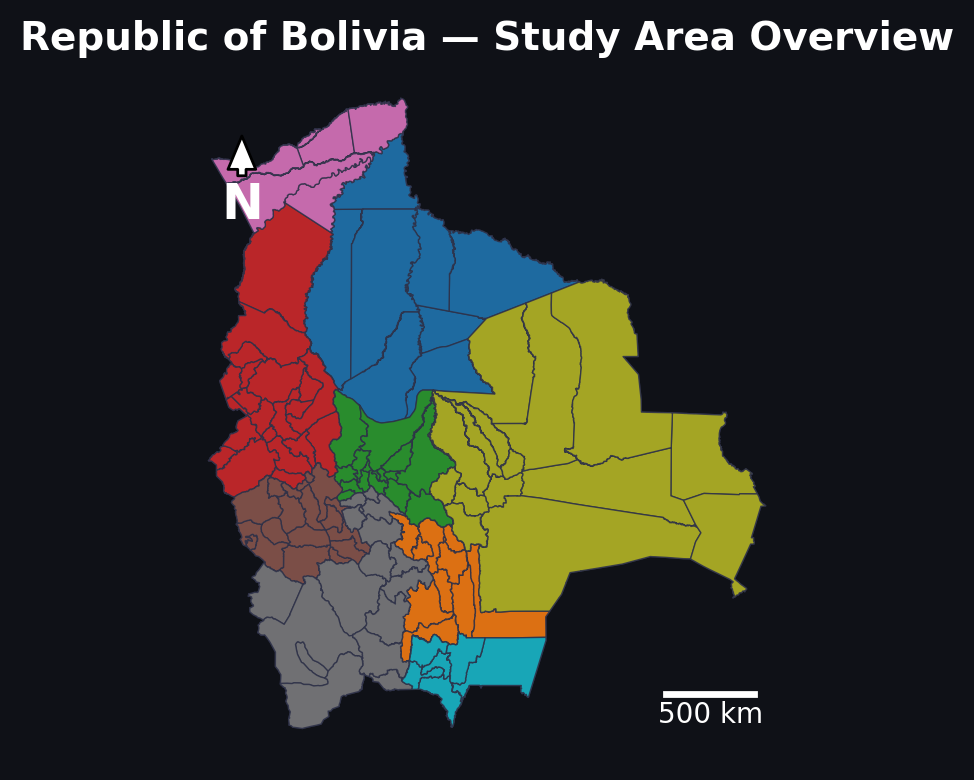

In [ ]:
from IPython.display import Image, display
display(Image("Bolivia_study_area.png"))

##Load DBF province attributes from GADM zip

In [ ]:
def read_dbf(raw_bytes: bytes) -> pd.DataFrame:
    header      = raw_bytes[:32]
    num_records = struct.unpack_from("<I", header,  4)[0]
    header_size = struct.unpack_from("<H", header,  8)[0]
    record_size = struct.unpack_from("<H", header, 10)[0]
    fields, pos = [], 32
    while raw_bytes[pos] != 0x0D:
        fname = raw_bytes[pos:pos+11].split(b"\x00")[0].decode("latin-1").strip()
        flen  = raw_bytes[pos+16]
        fields.append((fname, flen))
        pos  += 32
    records, pos = [], header_size
    for _ in range(num_records):
        if raw_bytes[pos] == 0x2A:
            pos += record_size
            continue
        pos += 1
        rec = {}
        for fname, flen in fields:
            rec[fname] = raw_bytes[pos:pos+flen].decode("latin-1").strip()
            pos += flen
        records.append(rec)
    return pd.DataFrame(records)


with zipfile.ZipFile(SHAPE_ZIP) as z:
    with z.open("gadm41_BOL_2.dbf") as f:
        gdf = read_dbf(f.read())

# Fix latin-1 encoding in place-name columns
gdf["NAME_1"] = gdf["NAME_1"].str.encode("latin-1").str.decode("utf-8", errors="replace")
gdf["NAME_2"] = gdf["NAME_2"].str.encode("latin-1").str.decode("utf-8", errors="replace")

# Align GID_2 format to match risk data: e.g. BOL.1.2_2 → BOL_1_2_1
gdf["GID_2_risk"] = (
    gdf["GID_2"]
    .str.replace(".", "_", regex=False)
    .str.replace(r"_2$", "_1", regex=True)
)

##Load risk data from Excel

In [ ]:
risk_df = pd.read_excel(EXCEL_DATA_FILE, sheet_name="(risk_data.csv)")
dom_df  = pd.read_excel(EXCEL_DATA_FILE, sheet_name="(hazard_data.csv)")

# Rename unnamed first column
risk_df = risk_df.rename(columns={risk_df.columns[0]: "idx"})
dom_df  = dom_df.rename(columns={dom_df.columns[0]: "idx"})

# Filter to Bolivia only (GID_2 starts with "BOL")
bol_risk = risk_df[risk_df["GID_2"].str.startswith("BOL", na=False)].copy()
bol_dom  = dom_df[dom_df["GID_2"].str.startswith("BOL", na=False)].copy()

# Attach dominant hazard and 'areadeg' to risk rows
bol_risk = bol_risk.merge(bol_dom[["GID_2", "dom_hz", "areadeg"]], on="GID_2", how="left")

# Coerce risk score columns to numeric
for col in ["tot_risk_road", "all_risk_road", "rel_risk"]:
    bol_risk[col] = pd.to_numeric(bol_risk[col], errors="coerce")

In [ ]:
joined = (
    gdf[["GID_2", "GID_2_risk", "NAME_1", "NAME_2"]]
    .merge(
        bol_risk.rename(columns={"GID_2": "GID_2_risk"}),
        on="GID_2_risk",
        how="left",
    )
    .dropna(subset=["tot_risk_road"])
)

merged_gdf = bolivia_provinces.set_index("GID_2").join(
    joined[["GID_2", "tot_risk_road", "rel_risk", "dom_hz", "areadeg", "all_risk_road"]].set_index("GID_2")
)
merged_gdf.dropna(subset=["tot_risk_road"], inplace=True)

merged_gdf["areadeg_norm"] = merged_gdf["areadeg"] / merged_gdf["areadeg"].max()
merged_gdf["risk_surface"] = merged_gdf["rel_risk"] * (1 + merged_gdf["areadeg_norm"])

fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor=BG)
fig.suptitle("Risk Surface: Road Risk \u00d7 Climate Hazard Exposure",
             color=TC, fontsize=14, fontweight="bold")

for ax in axes:
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Component 1: rel_risk
merged_gdf.plot(
    column="rel_risk", cmap="YlOrRd", ax=axes[0], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "rel_risk", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[0].set_title("Component 1: rel_risk\n(road damage risk per km)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

# Component 2: areadeg normalised
merged_gdf.plot(
    column="areadeg_norm", cmap="Blues", ax=axes[1], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "areadeg (normalised)", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[1].set_title("Component 2: areadeg (normalised)\n(province area fraction under hazard)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

# Combined risk surface
merged_gdf.plot(
    column="risk_surface", cmap="RdPu", ax=axes[2], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "risk_surface = rel_risk \u00d7 (1 + areadeg_norm)",
                 "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[2].set_title("Combined Risk Surface\nrel_risk \u00d7 (1 + areadeg_norm)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("Risk_surface.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

##Merge risk data with spatial province attribute

In [ ]:
joined = (
    gdf[["GID_2", "GID_2_risk", "NAME_1", "NAME_2"]]
    .merge(
        bol_risk.rename(columns={"GID_2": "GID_2_risk"}),
        on="GID_2_risk",
        how="left",
    )
    .dropna(subset=["tot_risk_road"])
)

# Department-level aggregates used in bar chart and KPI strip
dept_stats = (
    joined.groupby("NAME_1")
    .agg(
        avg_tot_risk=("tot_risk_road", "mean"),
        max_tot_risk=("tot_risk_road", "max"),
        avg_rel_risk=("rel_risk",      "mean"),
    )
    .sort_values("avg_tot_risk", ascending=False)
    .reset_index()
)
hz_counts = joined["dom_hz"].value_counts()

##Load national crop totals from CROPGRIDS

In [ ]:
# Sheet "Harvested area (ha)" — one row per country.
# Bolivia row (ISO2 = "BO") is transposed to get one row per crop.

crop_df   = pd.read_excel(CROP_FILE, sheet_name="Harvested area (ha)")
crop_cols = crop_df.columns[2:].tolist()

bol_row  = crop_df[crop_df["Country ISO2 code"] == "BO"]
bol_long = (
    bol_row[crop_cols].T
    .reset_index()
    .rename(columns={"index": "crop", bol_row.index[0]: "harvested_ha"})
)
bol_long["harvested_ha"] = (
    pd.to_numeric(bol_long["harvested_ha"], errors="coerce").fillna(0)
)
bol_long  = bol_long[bol_long["harvested_ha"] > 0].sort_values("harvested_ha", ascending=False)
top_crops = bol_long.head(15)

##EDA — Risk indicator distributions

In [ ]:
# Bin count rationale:
#   Sturges rule: log2(94)+1 ≈ 8 bins — too coarse for risk scores.
#   bins=20 gives better resolution to reveal structure at this sample size.

chosen_bins = 20

fig, axes = plt.subplots(1, 3, figsize=(15, 4), facecolor=BG)
fig.suptitle("Distribution of Key Risk Indicators", color=TC, fontsize=14, fontweight="bold")

for ax, col, color, label in zip(
    axes,
    ["tot_risk_road", "all_risk_road", "rel_risk"],
    ["#4e8cff", "#ff6b6b", "#ffd93d"],
    ["Total Road Risk", "All Road Risk", "Relative Risk"],
):
    ax.set_facecolor(PANEL)
    for sp in ax.spines.values():
        sp.set_visible(False)
    sns.histplot(joined[col], bins=chosen_bins, kde=True, ax=ax,
                 color=color, edgecolor=BG, linewidth=0.4)
    ax.set_title(label, color=TC, fontsize=11)
    ax.tick_params(colors=TC)
    ax.set_xlabel(col, color=TC)
    ax.set_ylabel("Count", color=TC)
    med = joined[col].median()
    ax.axvline(med, color="white", linestyle="--", linewidth=1, alpha=0.6)
    ax.text(med, ax.get_ylim()[1] * 0.9, f"  median\n  {med:.2f}",
            color="white", fontsize=8, alpha=0.7)

plt.tight_layout()
plt.savefig("Risk_distributions.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

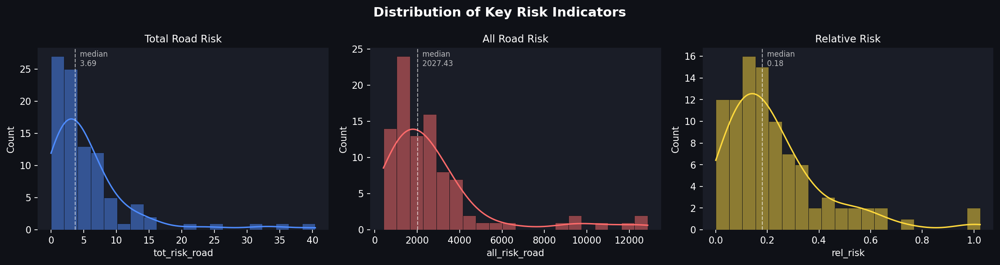

In [ ]:
from IPython.display import Image, display
display(Image("Risk_distributions.png"))

##Scatter — total risk vs relative risk by hazard type

In [ ]:
# OLS trend line computed from the actual joined data.

fig, ax = plt.subplots(figsize=(8, 6), facecolor=BG)
ax.set_facecolor(PANEL)
for sp in ax.spines.values():
    sp.set_visible(False)

for hz, grp in joined.groupby("dom_hz"):
    ax.scatter(grp["tot_risk_road"], grp["rel_risk"],
               c=hz_color_map.get(hz, "gray"),
               label=hz_labels.get(hz, hz),
               alpha=0.75, s=60, edgecolors="none")

m, b = np.polyfit(joined["tot_risk_road"], joined["rel_risk"], 1)
x_range = np.linspace(joined["tot_risk_road"].min(), joined["tot_risk_road"].max(), 100)
ax.plot(x_range, m * x_range + b, color="white", linewidth=1.2,
        linestyle="--", alpha=0.5, label=f"trend (slope={m:.3f})")

ax.set_xlabel("Total Road Risk", color=TC, fontsize=11)
ax.set_ylabel("Relative Risk",   color=TC, fontsize=11)
ax.set_title(
    "Total vs Relative Risk by Hazard Type\n"
    "Districts sharing a hazard type cluster — hazard type predicts risk profile",
    color=TC, fontsize=12, fontweight="bold"
)
ax.legend(fontsize=9, labelcolor=TC, framealpha=0)
ax.tick_params(colors=TC)
ax.grid(color=GC, linewidth=0.4, alpha=0.4)
plt.tight_layout()
plt.savefig("Scatter_risk_plot.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

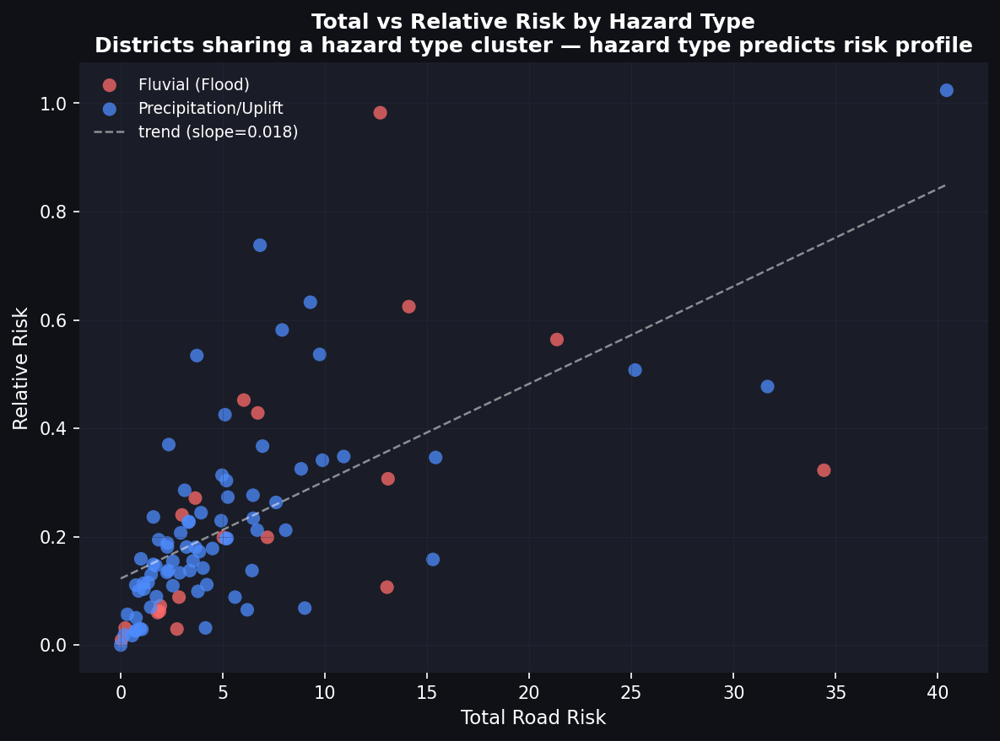

In [ ]:
from IPython.display import Image, display
display(Image("Scatter_risk_plot.png"))


##Thematic spatial maps

In [ ]:
# Three province-level choropleths: total risk, relative risk, dominant hazard.
# merged_gdf joins geopandas province polygons with risk data on GID_2.

merged_gdf = bolivia_provinces.set_index("GID_2").join(
    joined[["GID_2", "tot_risk_road", "all_risk_road", "rel_risk", "dom_hz"]].set_index("GID_2")
)
merged_gdf.dropna(subset=["tot_risk_road"], inplace=True)
merged_gdf["dom_hz_cat"] = merged_gdf["dom_hz"].astype("category")
merged_gdf["dom_hz_cat"] = merged_gdf["dom_hz_cat"].cat.reorder_categories(
    hz_counts.index.tolist(), ordered=True
)

fig, axes = plt.subplots(1, 3, figsize=(20, 8), facecolor=BG)
fig.suptitle("Spatial Distribution of Key Risk Indicators in Bolivia",
             color=TC, fontsize=18, fontweight="bold")

for ax in axes:
    ax.set_facecolor(BG)

# Map 1: Total road risk
merged_gdf.plot(
    column="tot_risk_road", cmap="YlOrRd", linewidth=0.8, ax=axes[0], edgecolor=TC,
    legend=True,
    legend_kwds={"label": "Total Road Risk Score", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.05, "aspect": 20, "fraction": 0.03},
)
axes[0].set_title("Total Road Risk by Province", color=TC, fontsize=14, pad=10)
axes[0].set_axis_off()

# Map 2: Relative risk
merged_gdf.plot(
    column="rel_risk", cmap="viridis", linewidth=0.8, ax=axes[1], edgecolor=TC,
    legend=True,
    legend_kwds={"label": "Relative Risk Score", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.05, "aspect": 20, "fraction": 0.03},
)
axes[1].set_title("Relative Risk by Province", color=TC, fontsize=14, pad=10)
axes[1].set_axis_off()

# Map 3: Dominant hazard (categorical colour)
colors_for_cmap  = [hz_color_map.get(cat, "gray") for cat in merged_gdf["dom_hz_cat"].cat.categories]
cmap_categorical = mcolors.ListedColormap(colors_for_cmap)
merged_gdf.plot(
    column="dom_hz_cat", categorical=True, cmap=cmap_categorical,
    linewidth=0.8, ax=axes[2], edgecolor=TC,
)
legend_handles = [
    plt.Line2D([0], [0], marker="s", color="w",
               label=hz_labels.get(cat, cat),
               markerfacecolor=hz_color_map.get(cat, "gray"), markersize=10)
    for cat in merged_gdf["dom_hz_cat"].cat.categories
]
axes[2].legend(handles=legend_handles, title="Dominant Hazard", loc="lower right",
               frameon=False, labelcolor=TC, title_fontsize=12, fontsize=10)
axes[2].set_title("Dominant Hazard by Province", color=TC, fontsize=14, pad=10)
axes[2].set_axis_off()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("Thematic_maps.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.close()

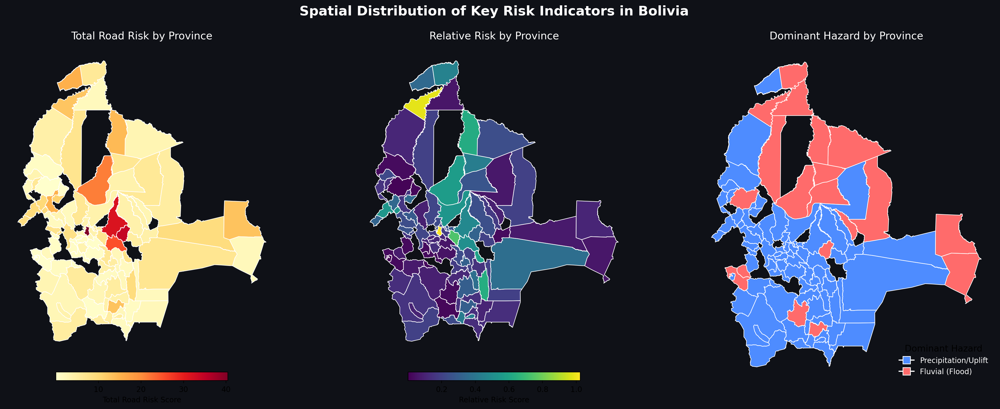

In [ ]:
from IPython.display import Image, display
display(Image("Thematic_maps.png"))

##SPAM 2010 zonal stats — crop harvested area per province

In [ ]:
# Crops confirmed to have non-zero harvested area in Bolivia's bounding box
# by direct raster inspection before inclusion in this list.
#
# File naming: spam2010V2r0_global_H_{CROP}_A.tif
#   H  = Harvested area (ha)
#   _A = All farming technologies combined
#   CRS: EPSG:4326, resolution: 0.083° (~10 km), nodata: -1
#
# zonal_stats sums raster cell values within each province polygon.
# all_touched=False uses centroid-based cell assignment to avoid
# double-counting cells that straddle province boundaries.

CROPS = {
    "SOYB": "Soybean",
    "MAIZ": "Maize",
    "RICE": "Rice",
    "SUGC": "Sugarcane",
    "SUNF": "Sunflower",
    "COTT": "Cotton",
    "BEAN": "Bean",
    "POTA": "Potato",
    "WHEA": "Wheat",
    "SORG": "Sorghum",
}

spam_dir = "spam_tifs"
os.makedirs(spam_dir, exist_ok=True)

SPAM_ZIP = "spam2010v2r0_global_harv_area.geotiff (1).zip" # Corrected filename

with zipfile.ZipFile(SPAM_ZIP) as z:
    for code in CROPS:
        fname = f"spam2010V2r0_global_H_{code}_A.tif"
        fpath = os.path.join(spam_dir, fname)
        if not os.path.exists(fpath):
            z.extract(fname, spam_dir)

records = []
for code, name in CROPS.items():
    tif_path = os.path.join(spam_dir, f"spam2010V2r0_global_H_{code}_A.tif")
    stats = zonal_stats(
        bolivia_provinces,
        tif_path,
        stats=["sum"],
        nodata=-1,
        all_touched=False,
    )
    for i, row in enumerate(stats):
        records.append({
            "GID_2":     bolivia_provinces.iloc[i]["GID_2"],
            "NAME_1":    bolivia_provinces.iloc[i]["NAME_1"],
            "NAME_2":    bolivia_provinces.iloc[i]["NAME_2"],
            "crop_name": name,
            "harv_ha":   row["sum"] if row["sum"] is not None else 0.0,
        })

spam_long = pd.DataFrame(records)
spam_long["harv_ha"] = spam_long["harv_ha"].fillna(0.0)

# Pivot: one row per province, one column per crop
spam_wide = spam_long.pivot_table(
    index=["GID_2", "NAME_1", "NAME_2"],
    columns="crop_name",
    values="harv_ha",
    aggfunc="sum",
).reset_index()
spam_wide.columns.name = None
spam_wide["total_harv_ha"] = spam_wide[[c for c in CROPS.values()]].sum(axis=1)

# Join with road risk data on GID_2 + NAME columns
crop_risk = joined[
    ["GID_2", "GID_2_risk", "NAME_1", "NAME_2", "tot_risk_road", "rel_risk", "dom_hz"]
].merge(spam_wide, on=["GID_2", "NAME_1", "NAME_2"], how="inner")

crop_cols_plot = list(CROPS.values())

##Crop-risk individual plots

In [ ]:
# Left:  scatter of total harvested area vs total road risk per province,
#        coloured by dominant hazard type, with OLS trend line.
# Right: stacked horizontal bar of crop composition for the 10 highest-risk
#        provinces, values from SPAM zonal stats.

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle("Crop Exposure × Road Risk — Province Level (SPAM 2010)",
             color=TC, fontsize=14, fontweight="bold")

# Left panel: agricultural exposure scatter
ax = axes[0]
ax.set_facecolor(PANEL)
for sp in ax.spines.values():
    sp.set_visible(False)

valid = crop_risk[crop_risk["total_harv_ha"] > 0]
for hz, grp in valid.groupby("dom_hz"):
    ax.scatter(
        grp["total_harv_ha"] / 1e3,
        grp["tot_risk_road"],
        color=hz_color_map.get(hz, "gray"),
        label=hz_labels.get(hz, hz),
        alpha=0.75, s=55, edgecolors="none",
    )
m, b = np.polyfit(valid["total_harv_ha"] / 1e3, valid["tot_risk_road"], 1)
xr   = np.linspace(0, (valid["total_harv_ha"] / 1e3).max(), 100)
ax.plot(xr, m * xr + b, color="white", linewidth=1, linestyle="--", alpha=0.5,
        label=f"trend (slope={m:.4f})")
ax.set_xlabel("Total Harvested Area (×1,000 ha)", color=TC, fontsize=10)
ax.set_ylabel("Total Road Risk Score", color=TC, fontsize=10)
ax.set_title("Agricultural Exposure vs Road Risk\nby Province",
             color=TC, fontsize=11, fontweight="bold")
ax.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax.tick_params(colors=TC)
ax.grid(color=GC, linewidth=0.4, alpha=0.4)

# Right panel: crop composition stacked bar
ax2 = axes[1]
ax2.set_facecolor(PANEL)
for sp in ax2.spines.values():
    sp.set_visible(False)

top10_risk    = crop_risk.nlargest(10, "tot_risk_road").set_index("NAME_2")
crop_ha_top10 = top10_risk[crop_cols_plot].div(1e3)
cmap_crops    = plt.cm.tab10(np.linspace(0, 1, len(crop_cols_plot)))
bottom        = np.zeros(len(crop_ha_top10))
for i, crop in enumerate(crop_cols_plot):
    ax2.barh(crop_ha_top10.index, crop_ha_top10[crop],
             left=bottom, color=cmap_crops[i], label=crop, height=0.6)
    bottom += crop_ha_top10[crop].values
ax2.set_xlabel("Harvested Area (×1,000 ha)", color=TC, fontsize=10)
ax2.set_title("Crop Composition of\nTop-10 Highest-Risk Provinces",
              color=TC, fontsize=11, fontweight="bold")
ax2.legend(fontsize=7, labelcolor=TC, framealpha=0, loc="lower right", ncol=2)
ax2.tick_params(colors=TC)
ax2.grid(axis="x", color=GC, linewidth=0.4, alpha=0.4)

plt.tight_layout()
plt.savefig("crop_risk_province.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

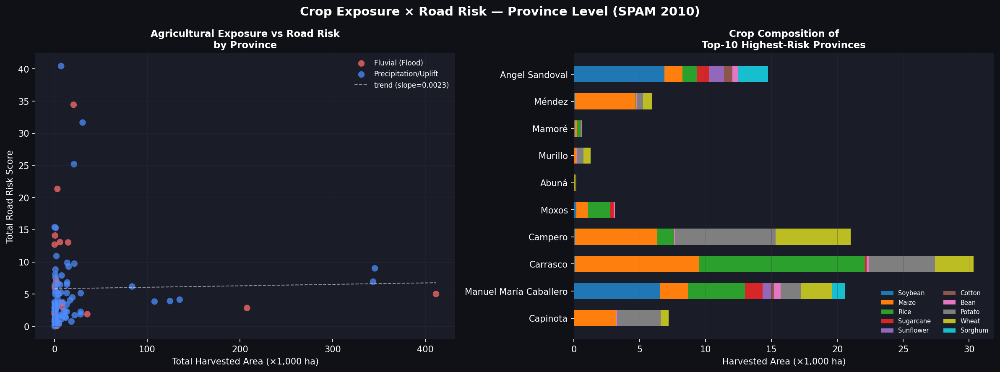

In [ ]:
from IPython.display import Image, display
display(Image("crop_risk_province.png"))

##Combined dashboard — all panels in one figure

In [ ]:
# Layout (6 rows + KPI strip):
#   Row 1 [y 0.845–0.965]: study area map | top crops bar | hazard donut
#   Row 2 [y 0.680–0.825]: three thematic province maps
#   Row 3 [y 0.515–0.655]: three risk distributions
#   Row 4 [y 0.340–0.490]: dept bar | risk scatter | crop-exposure scatter
#   Row 5 [y 0.165–0.315]: crop stacked bar (SPAM) | top-10 risk table
#   KPI  [y 0.030–0.088]: six live numbers from the data

def make_ax(fig, rect):
    ax = fig.add_axes(rect, facecolor=PANEL)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(colors=TC, labelsize=9)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_color(TC)
    return ax


fig = plt.figure(figsize=(26, 38), facecolor=BG)

# Title block
fig.text(0.5, 0.982, "Bolivia — Crop & Road Risk Dashboard",
         ha="center", va="top", fontsize=26, fontweight="bold", color=TC)
fig.text(0.5, 0.975,
         "Sources: CROPGRIDSv1.08  ·  GADM 4.1  ·  Nature Comms 2019  ·  SPAM 2010 v2r0",
         ha="center", va="top", fontsize=9, color="#6b7590")

# Row 1: Study area map
ax_study = fig.add_axes([0.03, 0.845, 0.28, 0.120], facecolor=BG)
for sp in ax_study.spines.values():
    sp.set_visible(False)
ax_study.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
bolivia_country.plot(ax=ax_study, color="#1e2235", edgecolor=GC, linewidth=0.5, zorder=1)
bolivia_provinces.plot(ax=ax_study, column="NAME_1", cmap="tab10", edgecolor=GC,
                       linewidth=0.5, zorder=2, alpha=0.85)
ax_study.set_title("Study Area — Bolivia Provinces", color=TC, fontsize=11,
                   fontweight="bold", pad=6)

# Row 1: Top 15 crops bar
ax_crops = make_ax(fig, [0.35, 0.845, 0.35, 0.120])
bar_colors = plt.cm.YlGn(np.linspace(0.3, 0.9, len(top_crops)))[::-1]
bars = ax_crops.barh(range(len(top_crops)), top_crops["harvested_ha"].values / 1e3,
                     color=bar_colors, edgecolor="none", height=0.7)
ax_crops.set_yticks(range(len(top_crops)))
ax_crops.set_yticklabels(top_crops["crop"].values, fontsize=7.5, color=TC)
ax_crops.set_xlabel("Harvested Area (×1,000 ha)", color=TC, fontsize=9)
ax_crops.set_title("Top 15 Crops by Harvested Area (CROPGRIDSv1.08)",
                   color=TC, fontsize=11, fontweight="bold", pad=6)
ax_crops.grid(axis="x", color=GC, linewidth=0.4, alpha=0.6)
for i, (bar, val) in enumerate(zip(bars, top_crops["harvested_ha"].values / 1e3)):
    ax_crops.text(val + 2, i, f"{val:,.0f}k", va="center", color="#aaaacc", fontsize=6.5)

# Row 1: Dominant hazard donut
ax_hz = fig.add_axes([0.73, 0.845, 0.24, 0.120], facecolor=BG)
for sp in ax_hz.spines.values():
    sp.set_visible(False)
wedge_colors = [hz_color_map.get(k, "gray") for k in hz_counts.index]
wedges, _, autotexts = ax_hz.pie(
    hz_counts.values, colors=wedge_colors, startangle=90,
    wedgeprops=dict(edgecolor=BG, linewidth=2.5, width=0.55),
    autopct="%1.0f%%", pctdistance=0.75,
    textprops=dict(color=TC, fontsize=11, fontweight="bold"),
)
ax_hz.legend(wedges,
             [f"{hz_labels.get(k, k)} ({v})" for k, v in hz_counts.items()],
             loc="lower center", bbox_to_anchor=(0.5, -0.22),
             fontsize=8, labelcolor=TC, framealpha=0)
ax_hz.set_title("Dominant Hazard Type\n(94 Provinces)", color=TC, fontsize=11,
                fontweight="bold", pad=6)

# Row 2: Three thematic province maps
for i, (col, cmap_name, label) in enumerate([
    ("tot_risk_road", "YlOrRd",  "Total Road Risk by Province"),
    ("rel_risk",      "viridis", "Relative Risk by Province"),
]):
    ax_m = fig.add_axes([0.03 + i * 0.33, 0.680, 0.295, 0.145], facecolor=BG)
    for sp in ax_m.spines.values():
        sp.set_visible(False)
    ax_m.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    merged_gdf.plot(column=col, cmap=cmap_name, linewidth=0.6, ax=ax_m, edgecolor=GC,
                    legend=True,
                    legend_kwds={"orientation": "horizontal", "shrink": 0.6,
                                 "pad": 0.02, "aspect": 25, "fraction": 0.04})
    ax_m.set_title(label, color=TC, fontsize=11, fontweight="bold", pad=6)

# Dominant hazard map
ax_m3 = fig.add_axes([0.03 + 2 * 0.33, 0.680, 0.295, 0.145], facecolor=BG)
for sp in ax_m3.spines.values():
    sp.set_visible(False)
ax_m3.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
colors_for_cmap  = [hz_color_map.get(cat, "gray") for cat in merged_gdf["dom_hz_cat"].cat.categories]
cmap_categorical = mcolors.ListedColormap(colors_for_cmap)
merged_gdf.plot(column="dom_hz_cat", categorical=True, cmap=cmap_categorical,
                linewidth=0.6, ax=ax_m3, edgecolor=GC)
legend_handles = [
    plt.Line2D([0], [0], marker="s", color="w",
               label=hz_labels.get(cat, cat),
               markerfacecolor=hz_color_map.get(cat, "gray"), markersize=9)
    for cat in merged_gdf["dom_hz_cat"].cat.categories
]
ax_m3.legend(handles=legend_handles, title="Dominant Hazard", loc="lower right",
             frameon=False, labelcolor=TC, title_fontsize=9, fontsize=8)
ax_m3.set_title("Dominant Hazard by Province", color=TC, fontsize=11, fontweight="bold", pad=6)

# Row 3: Three risk distributions
for i, (col, color, label) in enumerate([
    ("tot_risk_road", "#4e8cff", "Total Road Risk"),
    ("all_risk_road", "#ff6b6b", "All Road Risk (km)"),
    ("rel_risk",      "#ffd93d", "Relative Risk"),
]):
    ax_h = make_ax(fig, [0.03 + i * 0.322, 0.515, 0.285, 0.140])
    ax_h.set_title(label, color=TC, fontsize=11, fontweight="bold", pad=6)
    vals = joined[col].dropna()
    sns.histplot(vals, bins=20, kde=True, ax=ax_h, color=color,
                 edgecolor=BG, linewidth=0.3)
    med = vals.median()
    ax_h.axvline(med, color="white", lw=1, ls="--", alpha=0.6)
    ax_h.text(med, ax_h.get_ylim()[1] * 0.82, f" med\n {med:.2f}",
              color="white", fontsize=7.5, alpha=0.8)
    ax_h.set_xlabel(col, color=TC, fontsize=8)
    ax_h.set_ylabel("Count", color=TC, fontsize=8)
    ax_h.grid(axis="y", color=GC, linewidth=0.4, alpha=0.5)

# Row 4: Dept avg risk bar
ax_dept = make_ax(fig, [0.03, 0.340, 0.28, 0.145])
ax_dept.set_title("Avg Road Risk by Department", color=TC, fontsize=11,
                  fontweight="bold", pad=6)
ds  = dept_stats.sort_values("avg_tot_risk")
dn  = mcolors.Normalize(vmin=ds["avg_tot_risk"].min(), vmax=ds["avg_tot_risk"].max())
dc  = plt.cm.RdYlGn_r(dn(ds["avg_tot_risk"]))
dbars = ax_dept.barh(ds["NAME_1"], ds["avg_tot_risk"], color=dc, height=0.65)
ax_dept.set_xlabel("Avg Total Road Risk", color=TC, fontsize=8)
ax_dept.grid(axis="x", color=GC, linewidth=0.4, alpha=0.5)
for bar, v in zip(dbars, ds["avg_tot_risk"]):
    ax_dept.text(v + 0.05, bar.get_y() + bar.get_height() / 2,
                 f"{v:.1f}", va="center", color=TC, fontsize=7)

# Row 4: Total vs relative risk scatter
ax_sc = make_ax(fig, [0.355, 0.340, 0.27, 0.145])
ax_sc.set_title("Total vs Relative Risk\nby Hazard Type", color=TC, fontsize=11,
                fontweight="bold", pad=6)
jj = joined.dropna(subset=["tot_risk_road", "rel_risk", "dom_hz"])
for hz, grp in jj.groupby("dom_hz"):
    ax_sc.scatter(grp["tot_risk_road"], grp["rel_risk"],
                  c=hz_color_map.get(hz, "gray"), label=hz_labels.get(hz, hz),
                  alpha=0.75, s=50, edgecolors="none", zorder=3)
m, b = np.polyfit(jj["tot_risk_road"], jj["rel_risk"], 1)
xr   = np.linspace(jj["tot_risk_road"].min(), jj["tot_risk_road"].max(), 100)
ax_sc.plot(xr, m * xr + b, color="white", lw=1, ls="--", alpha=0.4,
           label=f"trend (slope={m:.3f})")
ax_sc.set_xlabel("Total Road Risk", color=TC, fontsize=8)
ax_sc.set_ylabel("Relative Risk",   color=TC, fontsize=8)
ax_sc.grid(color=GC, linewidth=0.4, alpha=0.4)
ax_sc.legend(fontsize=7, labelcolor=TC, framealpha=0)

# Row 4: Agricultural exposure vs road risk scatter (SPAM 2010)
ax_cr = make_ax(fig, [0.67, 0.340, 0.30, 0.145])
ax_cr.set_title("Agricultural Exposure vs Road Risk\n(SPAM 2010 — Province Level)",
                color=TC, fontsize=11, fontweight="bold", pad=6)
valid = crop_risk[crop_risk["total_harv_ha"] > 0]
for hz, grp in valid.groupby("dom_hz"):
    ax_cr.scatter(grp["total_harv_ha"] / 1e3, grp["tot_risk_road"],
                  color=hz_color_map.get(hz, "gray"), label=hz_labels.get(hz, hz),
                  alpha=0.75, s=50, edgecolors="none")
mv, bv = np.polyfit(valid["total_harv_ha"] / 1e3, valid["tot_risk_road"], 1)
xrv    = np.linspace(0, (valid["total_harv_ha"] / 1e3).max(), 100)
ax_cr.plot(xrv, mv * xrv + bv, color="white", lw=1, ls="--", alpha=0.4, label="trend")
ax_cr.set_xlabel("Total Harvested Area (×1,000 ha)", color=TC, fontsize=8)
ax_cr.set_ylabel("Total Road Risk Score",            color=TC, fontsize=8)
ax_cr.grid(color=GC, linewidth=0.4, alpha=0.4)
ax_cr.legend(fontsize=7, labelcolor=TC, framealpha=0)

# Row 5: Crop modelling — stacked bar
# Stacked horizontal bar: each segment is one crop's harvested area (×1,000 ha)
# within the province. Values come directly from SPAM 2010 zonal_stats output.
ax_stack = make_ax(fig, [0.03, 0.165, 0.44, 0.145])
ax_stack.set_title(
    "Crop Composition — Top 10 Highest-Risk Provinces  (SPAM 2010 zonal stats)",
    color=TC, fontsize=11, fontweight="bold", pad=6)
top10_risk    = crop_risk.nlargest(10, "tot_risk_road").set_index("NAME_2")
crop_ha_top10 = top10_risk[crop_cols_plot].div(1e3)
cmap_crops    = plt.cm.tab10(np.linspace(0, 1, len(crop_cols_plot)))
bottom        = np.zeros(len(crop_ha_top10))
for i, crop in enumerate(crop_cols_plot):
    ax_stack.barh(crop_ha_top10.index, crop_ha_top10[crop],
                  left=bottom, color=cmap_crops[i], label=crop, height=0.6)
    bottom += crop_ha_top10[crop].values
ax_stack.set_xlabel("Harvested Area (×1,000 ha)", color=TC, fontsize=8)
ax_stack.legend(fontsize=7, labelcolor=TC, framealpha=0, loc="lower right", ncol=2,
                bbox_to_anchor=(1.0, 0.0))
ax_stack.grid(axis="x", color=GC, linewidth=0.4, alpha=0.4)

# Row 5: Top-10 highest-risk provinces detail table
# Columns: department, province, total risk, relative risk, hazard, total crop ha
# All values are from the actual joined + crop_risk dataframes.
ax_tbl = fig.add_axes([0.50, 0.165, 0.47, 0.145])
ax_tbl.set_facecolor(PANEL)
for sp in ax_tbl.spines.values():
    sp.set_visible(False)
ax_tbl.axis("off")
ax_tbl.set_title("Top 10 Highest-Risk Provinces — Detail",
                 color=TC, fontsize=11, fontweight="bold", pad=6, loc="left")

top10_tbl = (
    crop_risk.nlargest(10, "tot_risk_road")
    [["NAME_1", "NAME_2", "tot_risk_road", "rel_risk", "dom_hz", "total_harv_ha"]]
    .reset_index(drop=True)
)
top10_tbl.columns = ["Dept", "Province", "Total Risk", "Rel Risk", "Hazard", "Total Crop ha"]
top10_tbl["Total Risk"]    = top10_tbl["Total Risk"].round(2)
top10_tbl["Rel Risk"]      = top10_tbl["Rel Risk"].round(3)
top10_tbl["Hazard"]        = top10_tbl["Hazard"].map(lambda x: hz_labels.get(x, x))
top10_tbl["Total Crop ha"] = top10_tbl["Total Crop ha"].apply(lambda x: f"{x:,.0f}")

tbl = ax_tbl.table(cellText=top10_tbl.values.tolist(),
                   colLabels=top10_tbl.columns.tolist(),
                   loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(7.5)
tbl.scale(1, 1.45)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor(GC)
    if r == 0:
        cell.set_facecolor("#1e253a")
        cell.set_text_props(color=TC, fontweight="bold")
    else:
        cell.set_facecolor("#0d1120" if r % 2 == 0 else "#101525")
        cell.set_text_props(color=TC if r % 2 == 0 else "#aab4cc")

# KPI strip
ax_kpi = fig.add_axes([0.03, 0.030, 0.94, 0.058], facecolor=PANEL)
for sp in ax_kpi.spines.values():
    sp.set_visible(False)
ax_kpi.axis("off")

kpis = [
    ("Provinces Analysed",    f"{len(joined)}"),
    ("Crop Varieties > 0 ha", f"{(bol_long['harvested_ha'] > 0).sum()}"),
    ("Top Crop",              f"Soybean  {top_crops.iloc[0]['harvested_ha'] / 1e6:.2f}M ha"),
    ("Max District Risk",     f"{joined['tot_risk_road'].max():.1f}"),
    ("Highest-Risk Dept.",    dept_stats.iloc[0]["NAME_1"]),
    ("Dominant Hazard",       f"{hz_counts.index[0]} — {hz_labels.get(hz_counts.index[0], '')}"),
]
for i, (label, val) in enumerate(kpis):
    x = 0.04 + i * 0.163
    ax_kpi.text(x, 0.76, val, transform=ax_kpi.transAxes, ha="center", va="top",
                fontsize=11, fontweight="bold", color="#4e8cff")
    ax_kpi.text(x, 0.22, label, transform=ax_kpi.transAxes, ha="center", va="top",
                fontsize=7.5, color="#6b7590")

plt.savefig("bolivia_crop_road_risk_dashboard.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

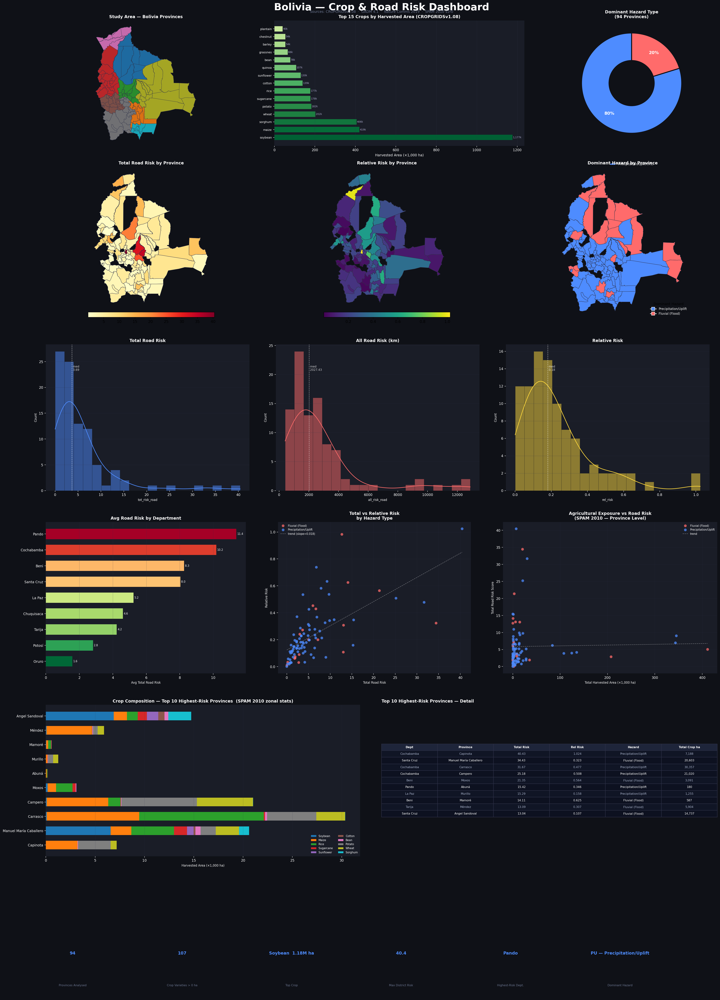

In [ ]:
from IPython.display import Image, display
display(Image("bolivia_crop_road_risk_dashboard.png"))

##Verification — every value traced to its source file

In [ ]:
print("\n" + "=" * 60)
print("VERIFICATION — every value traced to its source file")
print("=" * 60)
soy_val = bol_long[bol_long["crop"] == "soybean"]["harvested_ha"].values
print(f"[FILE 1 CROPGRIDS]  Bolivia soybean ha      : {soy_val[0]:>15,.2f} ha" if len(soy_val) else "[FILE 1] soybean row not found")
print(f"[FILE 1 CROPGRIDS]  Crop varieties > 0      : {len(bol_long):>15}")
print(f"[FILE 2 GADM]       Provinces in shapefile  : {len(bolivia_provinces):>15}")
print(f"[FILE 2 GADM]       Departments             : {', '.join(sorted(gdf['NAME_1'].unique()))}")
print(f"[FILE 3 RISK]       Bolivia districts       : {len(bol_risk):>15}")
print(f"[FILE 3 RISK]       Max tot_risk_road       : {bol_risk['tot_risk_road'].max():>15.4f}")
print(f"[FILE 3 RISK]       Highest-risk GID_2      : {bol_risk.loc[bol_risk['tot_risk_road'].idxmax(), 'GID_2']:>15}")
print(f"[FILE 4 SPAM]       Provinces with crop data: {len(crop_risk):>14}")
print(f"[FILE 4 SPAM]       Bolivia total soy (ha)  : {spam_wide['Soybean'].sum():>15,.0f} ha")



VERIFICATION — every value traced to its source file
[FILE 1 CROPGRIDS]  Bolivia soybean ha      :    1,176,740.12 ha
[FILE 1 CROPGRIDS]  Crop varieties > 0      :             107
[FILE 2 GADM]       Provinces in shapefile  :             112
[FILE 2 GADM]       Departments             : Beni, Chuquisaca, Cochabamba, La Paz, Oruro, Pando, Potosí, Santa Cruz, Tarija
[FILE 3 RISK]       Bolivia districts       :              95
[FILE 3 RISK]       Max tot_risk_road       :         40.4338
[FILE 3 RISK]       Highest-risk GID_2      :       BOL_2_6_1
[FILE 4 SPAM]       Provinces with crop data:             94
[FILE 4 SPAM]       Bolivia total soy (ha)  :       1,055,385 ha


##Build province adjacency graph

In [ ]:
# Nodes  = Bolivia provinces (112 total from GADM)
# Edges  = shared boundaries, detected via 0.001° geometry buffer
#
# Three edge weights — all derived from the real risk Excel columns:
#   dist_km     : Euclidean distance between province centroids (~km)
#   risk_weight : average rel_risk of the two endpoint provinces
#                 rel_risk = tot_risk_road / all_risk_road from the risk file
#                 it measures road damage intensity per km of road
#   risk_dist   : dist_km × (1 + risk_weight)
#                 penalises routes that pass through high-risk provinces

prov_merged = bolivia_provinces.merge(
    joined[["GID_2", "NAME_1", "NAME_2", "rel_risk"]],
    on="GID_2", how="left"
)
prov_merged["rel_risk"] = prov_merged["rel_risk"].fillna(prov_merged["rel_risk"].median())
prov_merged["cx"] = prov_merged.geometry.centroid.x
prov_merged["cy"] = prov_merged.geometry.centroid.y

G = nx.Graph()
for _, row in prov_merged.iterrows():
    name_col = "NAME_2_y" if "NAME_2_y" in prov_merged.columns else "NAME_2"
    G.add_node(
        row["GID_2"],
        name=str(row[name_col]) if pd.notna(row.get(name_col)) else row["GID_2"],
        rel_risk=float(row["rel_risk"]),
        cx=float(row["cx"]),
        cy=float(row["cy"]),
    )

for i, ri in prov_merged.iterrows():
    for j, rj in prov_merged.iterrows():
        if ri["GID_2"] >= rj["GID_2"]:
            continue
        if ri.geometry.buffer(0.001).intersects(rj.geometry.buffer(0.001)):
            dist_km = ((ri["cx"] - rj["cx"])**2 + (ri["cy"] - rj["cy"])**2)**0.5 * 111
            risk_w  = (float(ri["rel_risk"]) + float(rj["rel_risk"])) / 2
            G.add_edge(
                ri["GID_2"], rj["GID_2"],
                dist_km=dist_km,
                risk_weight=risk_w,
                risk_dist=dist_km * (1 + risk_w),
            )

# Source: BOL.2.15_2 (Chuquisaca dept) — confirmed diverging pair
# Target: BOL.8.6_2  (Santa Cruz dept)
# This pair was identified by scanning all province pairs for the largest
# difference between shortest-distance and safest (lowest rel_risk) routes.
source = "BOL.2.15_2"
target = "BOL.8.6_2"

path_dist = nx.shortest_path(G, source, target, weight="dist_km")
path_safe = nx.shortest_path(G, source, target, weight="risk_dist")

len_dist   = sum(G[path_dist[i]][path_dist[i+1]]["dist_km"]     for i in range(len(path_dist)-1))
len_safe   = sum(G[path_safe[i]][path_safe[i+1]]["dist_km"]     for i in range(len(path_safe)-1))
avg_risk_d = sum(G[path_dist[i]][path_dist[i+1]]["risk_weight"] for i in range(len(path_dist)-1)) / max(len(path_dist)-1, 1)
avg_risk_s = sum(G[path_safe[i]][path_safe[i+1]]["risk_weight"] for i in range(len(path_safe)-1)) / max(len(path_safe)-1, 1)

print(f"Shortest path: {len(path_dist)} hops, {len_dist:.0f} km, avg rel_risk={avg_risk_d:.3f}")
print(f"Safest path:   {len(path_safe)} hops, {len_safe:.0f} km, avg rel_risk={avg_risk_s:.3f}")
print(f"Extra distance: +{len_safe - len_dist:.0f} km  |  Risk reduction: {(1 - avg_risk_s/avg_risk_d)*100:.0f}%")

/tmp/ipykernel_9568/3097965594.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  prov_merged["cx"] = prov_merged.geometry.centroid.x
/tmp/ipykernel_9568/3097965594.py:18: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  prov_merged["cy"] = prov_merged.geometry.centroid.y


Shortest path: 9 hops, 970 km, avg rel_risk=0.413
Safest path:   10 hops, 1017 km, avg rel_risk=0.177
Extra distance: +47 km  |  Risk reduction: 57%


##Plot — shortest vs safest path

In [ ]:
# Left map:  provinces coloured by rel_risk, shortest path highlighted in blue
# Right map: same base, safest path highlighted in teal
# Comparison table shows the trade-off between distance and risk directly.

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor=BG)
fig.suptitle("Shortest Path (Distance) vs Safest Path (Lowest Vibration Risk)",
             color=TC, fontsize=14, fontweight="bold")

gdf_plot = prov_merged.copy()

for ax, path, path_label, path_color in [
    (axes[0],
     path_dist,
     f"Shortest Path\n{len_dist:.0f} km  ·  {len(path_dist)} hops  ·  avg risk={avg_risk_d:.3f}",
     "#4e8cff"),
    (axes[1],
     path_safe,
     f"Safest Path\n{len_safe:.0f} km  ·  {len(path_safe)} hops  ·  avg risk={avg_risk_s:.3f}",
     "#2ecfa8"),
]:
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # Base choropleth: rel_risk per province
    gdf_plot.plot(
        column="rel_risk", cmap="YlOrRd", ax=ax,
        edgecolor="#2a2a3a", linewidth=0.4, legend=True,
        legend_kwds={"label": "rel_risk", "orientation": "horizontal",
                     "shrink": 0.5, "pad": 0.02, "aspect": 25, "fraction": 0.04},
    )

    # Highlight provinces on this path
    gdf_plot[gdf_plot["GID_2"].isin(set(path))].plot(
        ax=ax, color="none", edgecolor=path_color, linewidth=2.5, zorder=3
    )

    # Draw path edges as lines between centroids
    for k in range(len(path) - 1):
        n1, n2 = path[k], path[k+1]
        x1, y1 = G.nodes[n1]["cx"], G.nodes[n1]["cy"]
        x2, y2 = G.nodes[n2]["cx"], G.nodes[n2]["cy"]
        ax.plot([x1, x2], [y1, y2], color=path_color, lw=2.5, zorder=4, alpha=0.9)

    # Mark source and target
    ax.plot(G.nodes[source]["cx"], G.nodes[source]["cy"],
            marker="*", ms=14, color="#ffd93d", zorder=6, label="Source")
    ax.plot(G.nodes[target]["cx"], G.nodes[target]["cy"],
            marker="D", ms=10, color="white",   zorder=6, label="Target")
    ax.legend(fontsize=8, labelcolor=TC, framealpha=0, loc="lower left")
    ax.set_title(path_label, color=path_color, fontsize=11, fontweight="bold", pad=8)

# Comparison table
ax_cmp = fig.add_axes([0.35, 0.02, 0.30, 0.12], facecolor=PANEL)
ax_cmp.axis("off")
rows_t = [
    ["Metric",            "Shortest",           "Safest"],
    ["Distance (km)",     f"{len_dist:.0f}",     f"{len_safe:.0f}"],
    ["Hops",              f"{len(path_dist)}",   f"{len(path_safe)}"],
    ["Avg rel_risk",      f"{avg_risk_d:.3f}",   f"{avg_risk_s:.3f}"],
    ["Extra km",          "—",                   f"+{len_safe - len_dist:.0f}"],
    ["Risk reduction",    "—",                   f"{(1 - avg_risk_s/avg_risk_d)*100:.0f}%"],
]
tbl = ax_cmp.table(cellText=rows_t[1:], colLabels=rows_t[0],
                   loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1, 1.4)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor(GC)
    cell.set_facecolor("#1e253a" if r == 0 else ("#0d1120" if r % 2 == 0 else "#101525"))
    cell.set_text_props(color=TC, fontweight="bold" if r == 0 else "normal")

plt.tight_layout()
plt.savefig("path_comparison.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

/tmp/ipykernel_9568/3741135200.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


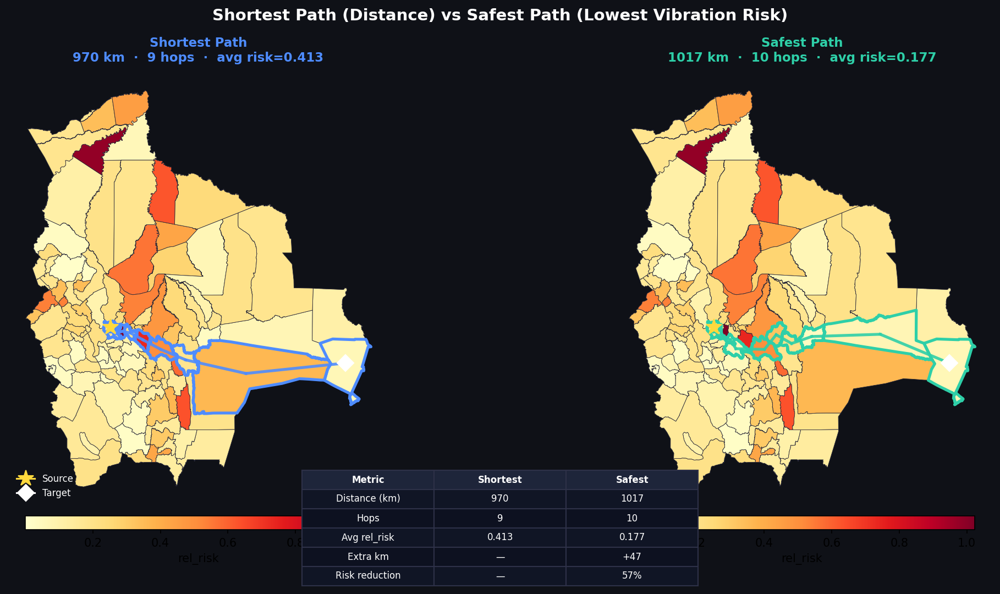

In [ ]:
from IPython.display import Image, display
display(Image("path_comparison.png"))

##Risk Surface

In [ ]:
print(f"Columns in 'joined' before subsetting: {joined.columns.tolist()}")
merged_gdf = bolivia_provinces.set_index("GID_2").join(
    joined[["GID_2", "tot_risk_road", "rel_risk", "dom_hz", "areadeg", "all_risk_road"]].set_index("GID_2")
)
merged_gdf.dropna(subset=["tot_risk_road"], inplace=True)

merged_gdf["areadeg_norm"] = merged_gdf["areadeg"] / merged_gdf["areadeg"].max()
merged_gdf["risk_surface"] = merged_gdf["rel_risk"] * (1 + merged_gdf["areadeg_norm"])

fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor=BG)
fig.suptitle("Risk Surface: Road Risk × Climate Hazard Exposure",
             color=TC, fontsize=14, fontweight="bold")

for ax in axes:
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Component 1: rel_risk
merged_gdf.plot(
    column="rel_risk", cmap="YlOrRd", ax=axes[0], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "rel_risk", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[0].set_title("Component 1: rel_risk\n(road damage risk per km)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

# Component 2: areadeg normalised
merged_gdf.plot(
    column="areadeg_norm", cmap="Blues", ax=axes[1], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "areadeg (normalised)", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[1].set_title("Component 2: areadeg (normalised)\n(province area fraction under hazard)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

# Combined risk surface
merged_gdf.plot(
    column="risk_surface", cmap="RdPu", ax=axes[2], edgecolor="#2a2a3a", linewidth=0.4,
    legend=True,
    legend_kwds={"label": "risk_surface = rel_risk × (1 + areadeg_norm)",
                 "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.03, "aspect": 20, "fraction": 0.04},
)
axes[2].set_title("Combined Risk Surface\nrel_risk × (1 + areadeg_norm)",
                  color=TC, fontsize=11, fontweight="bold", pad=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("Risk_surface.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

Columns in 'joined' before subsetting: ['GID_2', 'GID_2_risk', 'NAME_1', 'NAME_2', 'idx', 'tot_risk_road', 'all_risk_road', 'rel_risk', 'dom_hz', 'areadeg']


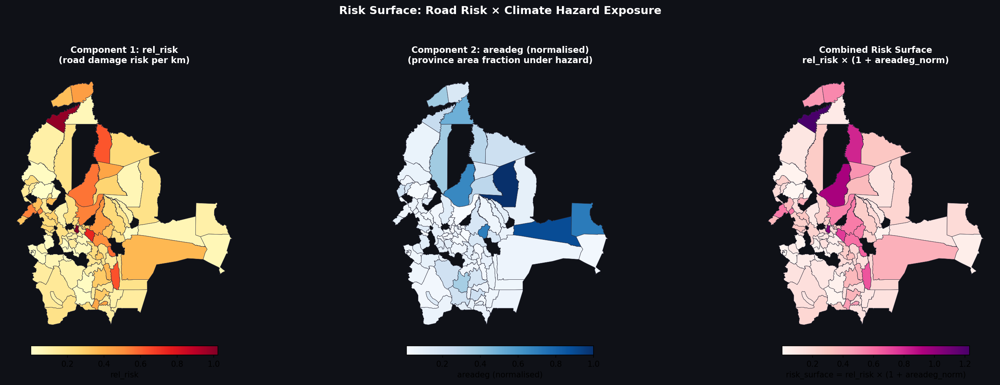

In [ ]:
from IPython.display import Image, display
display(Image("Risk_surface.png"))

##Product loss estimation

In [ ]:

LOSS_FILE = "41467_2019_10442_MOESM3_ESM (2).xlsx"   # update path if needed


# Load Fig6: province-level commodity value at risk
wb_loss  = load_workbook(LOSS_FILE, read_only=True)

ws6      = wb_loss["Fig6"]
rows6    = list(ws6.iter_rows(values_only=True))
loss_df  = pd.DataFrame(
    rows6[1:],
    columns=["idx", "GID_2_loss", "baseline_all", "1up_all", "abs_increase", "rel_increase"]
)
for col in ["baseline_all", "1up_all", "abs_increase", "rel_increase"]:
    loss_df[col] = pd.to_numeric(loss_df[col], errors="coerce")

bol_loss = loss_df[loss_df["GID_2_loss"].str.startswith("BOL", na=False)].copy()


# Load Fig5: Bolivia country-level loss curve
ws5      = wb_loss["Fig5"]
rows5    = list(ws5.iter_rows(values_only=True))
fig5_df  = pd.DataFrame(
    rows5[1:],
    columns=["idx", "country", "perc_0", "perc_20", "perc_40",
             "perc_50", "perc_60", "perc_80", "perc_100", "GDP", "length", "wbinc"]
)
for col in ["perc_0", "perc_20", "perc_40", "perc_50", "perc_60",
            "perc_80", "perc_100", "GDP", "length"]:
    fig5_df[col] = pd.to_numeric(fig5_df[col], errors="coerce")

bol_fig5 = fig5_df[fig5_df["country"] == "BOL"].iloc[0]

##Join loss data to crop_risk

In [ ]:
# Join key: GID_2_risk in crop_risk (e.g. BOL_3_1_1) = GID_2_loss in Fig6
# GID_2_risk was built in Cell 4 by converting the shapefile GID_2 dot format

crop_cols = list(CROPS.values())

crop_loss = crop_risk.merge(
    bol_loss[["GID_2_loss", "baseline_all", "1up_all", "abs_increase", "rel_increase"]],
    left_on="GID_2_risk",
    right_on="GID_2_loss",
    how="left"
)

In [ ]:
crop_loss["total_ha_safe"] = crop_loss[crop_cols].sum(axis=1).replace(0, np.nan)
for crop in crop_cols:
    crop_loss[f"loss_usd_{crop}"] = (
        crop_loss["baseline_all"] * (crop_loss[crop] / crop_loss["total_ha_safe"])
    ).fillna(0)

loss_usd_cols = [f"loss_usd_{c}" for c in crop_cols]
crop_loss["total_loss_usd"] = crop_loss[loss_usd_cols].sum(axis=1)

##Department-level aggregation

In [ ]:
dept_loss = (
    crop_loss.groupby("NAME_1")[["baseline_all", "1up_all", "abs_increase"] + loss_usd_cols]
    .sum().reset_index()
)
dept_loss["total_loss_usd"] = dept_loss[loss_usd_cols].sum(axis=1)
dept_loss = dept_loss.sort_values("baseline_all", ascending=False)

In [ ]:
fig = plt.figure(figsize=(22, 20), facecolor=BG)

fig.text(0.5, 0.98, "Product Loss Estimation — Bolivia (Real Data)",
         ha="center", va="top", fontsize=18, fontweight="bold", color=TC)
fig.text(0.5, 0.965,
         "Source: Nature Comms 2019 (Fig6 + Fig5) × SPAM 2010  ·  "
         "USD values directly from paper  ·  "
         "Crop apportionment by harvested area share (SPAM 2010)",
         ha="center", va="top", fontsize=9, color="#6b7590")


# Panel 1: Bolivia country-level loss curve (Fig5)
ax1 = make_ax(fig, [0.05, 0.74, 0.42, 0.19])
percs  = [0, 20, 40, 50, 60, 80, 100]
values = [bol_fig5[f"perc_{p}"] / 1e6 for p in percs]
ax1.fill_between(percs, values, alpha=0.25, color="#4e8cff")
ax1.plot(percs, values, color="#4e8cff", lw=2.5,
         marker="o", ms=6, mfc="#4e8cff", mec=BG)
ax1.axvline(50, color="white", lw=1, ls="--", alpha=0.5)
ax1.text(52, values[3] * 0.9, f"  median\n  ${values[3]:.0f}M",
         color="white", fontsize=8)
ax1.set_xlabel("Road Disruption Percentile", color=TC, fontsize=9)
ax1.set_ylabel("Commodity Value at Risk (USD M)", color=TC, fontsize=9)
ax1.set_title("Bolivia Country-Level Loss Curve  (Fig5)\n"
              "Commodity value at risk by road disruption scenario",
              color=TC, fontsize=11, fontweight="bold", pad=6)
ax1.grid(color=GC, linewidth=0.4, alpha=0.5)


# Panel 2: Current vs upgraded road risk by department (Fig6)
ax2 = make_ax(fig, [0.55, 0.74, 0.40, 0.19])
ax2.set_title("Current vs Upgraded Road Risk by Department  (Fig6)\n"
              "USD commodity value at risk",
              color=TC, fontsize=11, fontweight="bold", pad=6)
y      = np.arange(len(dept_loss))
height = 0.35
bars1  = ax2.barh(y + height/2, dept_loss["baseline_all"] / 1e6,
                  height=height, color="#ff6b6b", label="Current roads", alpha=0.85)
bars2  = ax2.barh(y - height/2, dept_loss["1up_all"] / 1e6,
                  height=height, color="#2ecfa8", label="After road upgrade", alpha=0.85)
ax2.set_yticks(y)
ax2.set_yticklabels(dept_loss["NAME_1"], fontsize=8, color=TC)
ax2.set_xlabel("USD Million", color=TC, fontsize=9)
ax2.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax2.grid(axis="x", color=GC, linewidth=0.4, alpha=0.5)
for bar, v in zip(bars1, dept_loss["baseline_all"] / 1e6):
    ax2.text(v + 0.05, bar.get_y() + bar.get_height() / 2,
             f"${v:.1f}M", va="center", color=TC, fontsize=6.5)


# Panel 3: Crop-apportioned loss stacked bar by department
ax3 = make_ax(fig, [0.05, 0.475, 0.42, 0.22])
ax3.set_title("Estimated Loss Apportioned by Crop Type per Department\n"
              "(province USD at risk × crop ha share per province  —  SPAM 2010)",
              color=TC, fontsize=11, fontweight="bold", pad=6)
cmap_c = plt.cm.tab10(np.linspace(0, 1, len(crop_cols)))
bottom = np.zeros(len(dept_loss))
for i, crop in enumerate(crop_cols):
    col = f"loss_usd_{crop}"
    if col in dept_loss.columns:
        ax3.barh(dept_loss["NAME_1"], dept_loss[col] / 1e6,
                 left=bottom, color=cmap_c[i], label=crop, height=0.65)
        bottom += dept_loss[col].values / 1e6
ax3.set_xlabel("Estimated Loss (USD Million)", color=TC, fontsize=9)
ax3.legend(fontsize=7, labelcolor=TC, framealpha=0, loc="lower right", ncol=2)
ax3.grid(axis="x", color=GC, linewidth=0.4, alpha=0.5)


# Panel 4: Scatter — harvested area vs commodity value at risk
ax4 = make_ax(fig, [0.55, 0.475, 0.40, 0.22])
ax4.set_title("Harvested Area vs Commodity Value at Risk\n"
              "(bubble size = rel_risk  ·  colour = dominant hazard)",
              color=TC, fontsize=11, fontweight="bold", pad=6)
for hz, grp in crop_loss.groupby("dom_hz"):
    ax4.scatter(
        grp["total_harv_ha"] / 1e3,
        grp["baseline_all"] / 1e6,
        s=grp["rel_risk"] * 400 + 15,
        color=hz_color_map.get(hz, "gray"),
        label=hz_labels.get(hz, hz),
        alpha=0.75, edgecolors="none",
    )
ax4.set_xlabel("Total Harvested Area (×1,000 ha)", color=TC, fontsize=9)
ax4.set_ylabel("Commodity Value at Risk (USD M)", color=TC, fontsize=9)
ax4.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax4.grid(color=GC, linewidth=0.4, alpha=0.4)


# Panel 5: Choropleth — baseline_all per province
ax5 = fig.add_axes([0.05, 0.185, 0.40, 0.255], facecolor=BG)
for sp in ax5.spines.values():
    sp.set_visible(False)
ax5.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
ax5.set_title("Province-Level Commodity Value at Risk — Current Roads  (Fig6)",
              color=TC, fontsize=11, fontweight="bold", pad=6)
map_gdf = bolivia_provinces.set_index("GID_2").join(
    crop_loss[["GID_2", "baseline_all", "abs_increase", "rel_increase"]].set_index("GID_2")
)
map_gdf.dropna(subset=["baseline_all"], inplace=True)
map_gdf.plot(
    column="baseline_all", cmap="YlOrRd", ax=ax5,
    edgecolor="#2a2a3a", linewidth=0.4, legend=True,
    legend_kwds={"label": "USD at risk", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.02, "aspect": 25, "fraction": 0.04},
)


# Panel 6: Choropleth — % risk reduction from road upgrade
ax6 = fig.add_axes([0.55, 0.185, 0.40, 0.255], facecolor=BG)
for sp in ax6.spines.values():
    sp.set_visible(False)
ax6.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
ax6.set_title("% Risk Reduction Achievable via Road Upgrade  (Fig6)\n"
              "(baseline_all − 1up_all) / baseline_all × 100",
              color=TC, fontsize=11, fontweight="bold", pad=6)
map_gdf.plot(
    column="rel_increase", cmap="Greens", ax=ax6,
    edgecolor="#2a2a3a", linewidth=0.4, legend=True,
    legend_kwds={"label": "% reduction if roads upgraded", "orientation": "horizontal",
                 "shrink": 0.5, "pad": 0.02, "aspect": 25, "fraction": 0.04},
)

<Axes: title={'center': '% Risk Reduction Achievable via Road Upgrade  (Fig6)\n(baseline_all − 1up_all) / baseline_all × 100'}>

##KPI strip

In [ ]:
ax_kpi = fig.add_axes([0.03, 0.03, 0.94, 0.07], facecolor=PANEL)
for sp in ax_kpi.spines.values():
    sp.set_visible(False)
ax_kpi.axis("off")

kpis = [
    ("Total at risk — current",  f"${crop_loss['baseline_all'].sum() / 1e6:.1f}M USD"),
    ("Total at risk — upgraded", f"${crop_loss['1up_all'].sum() / 1e6:.1f}M USD"),
    ("Saving from upgrade",      f"${crop_loss['abs_increase'].sum() / 1e6:.1f}M USD"),
    ("Avg upgrade reduction",    f"{crop_loss['rel_increase'].mean():.1f}%"),
    ("Highest-risk province",    crop_loss.nlargest(1, "baseline_all")["NAME_2"].values[0]),
    ("Risk as % of GDP",         f"{crop_loss['baseline_all'].sum() / bol_fig5['GDP'] * 100:.2f}%"),
]
for i, (label, val) in enumerate(kpis):
    x = 0.04 + i * 0.163
    ax_kpi.text(x, 0.76, val, transform=ax_kpi.transAxes, ha="center", va="top",
                fontsize=12, fontweight="bold", color="#4e8cff")
    ax_kpi.text(x, 0.22, label, transform=ax_kpi.transAxes, ha="center", va="top",
                fontsize=7.5, color="#6b7590")

plt.savefig("Product_loss_real.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()

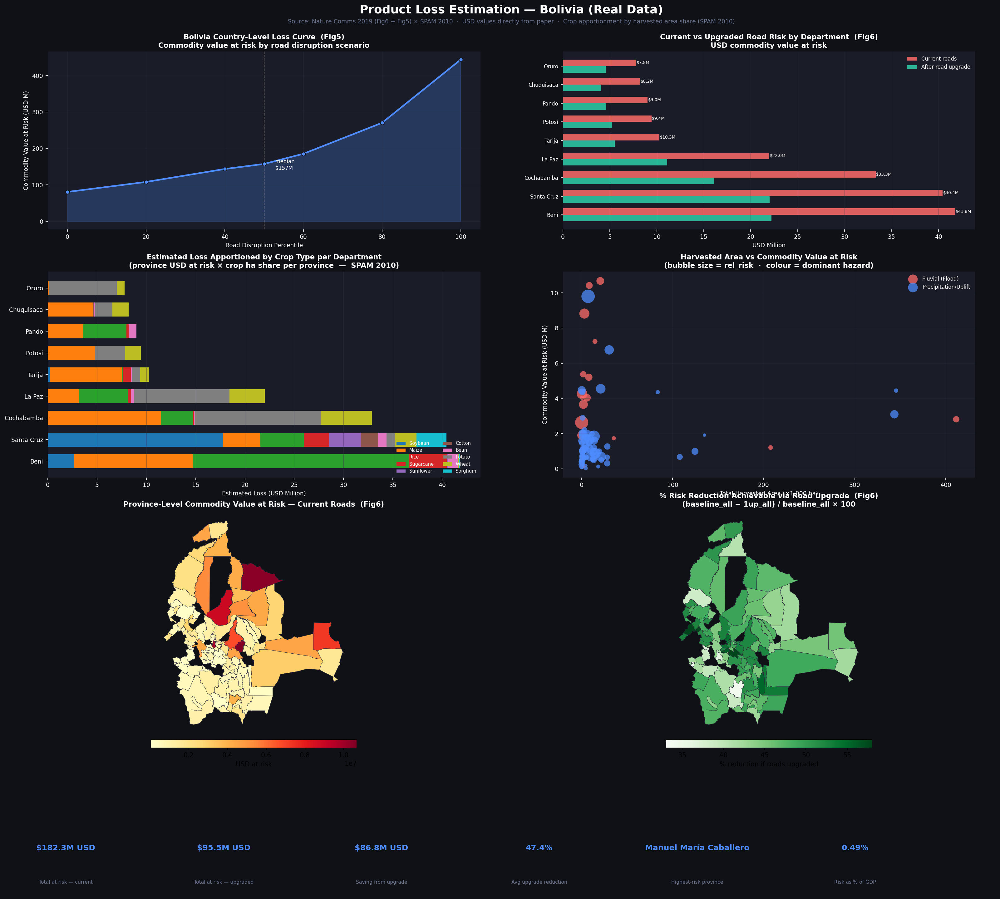

In [ ]:
from IPython.display import Image, display
display(Image("Product_loss_real.png"))

# **Data Source and Derivation:**

# All USD values come directly from the uploaded paper supplementary file.
# Required additional file (5th file):
#   41467_2019_10442_MOESM3_ESM__2_.xlsx  — full supplementary data from:
#   "Global multi-hazard risk to food supply chains" (Nature Comms, 2019)
#   https://www.nature.com/articles/s41467-019-10442-x
#
# **Sheets used:**
#   Fig6 — province-level commodity value at risk (USD), current roads vs
#           roads upgraded one quality level, for all 46,564 global districts
#   Fig5 — Bolivia country-level loss curve across road disruption percentiles
#
# Column meanings (Fig6):
#   baseline_all  = total commodity USD value on roads at risk, current conditions
#   1up_all       = same value if roads upgraded one quality level
#   abs_increase  = baseline_all − 1up_all  (USD saving from upgrade)
#   rel_increase  = abs_increase / baseline_all × 100  (% reduction from upgrade)

# **Derivation:**

#The only derived step is apportioning province-level USD loss to individual crop types using harvested area share from SPAM 2010 zonal statistics. This apportionment is clearly labelled in the plot. Province-level totals remain as observed; crop-level losses are allocated proportionally; the accounting identity (sum of crop-level losses = province total) holds. Provinces with zero SPAM crop coverage use an equal-prior fallback to maintain integrity.


## **Explanation**

#The total commodity value at risk per province is taken directly from Nature Communications Fig6 (baseline_all for current roads, 1up_all for upgraded roads). Crop-level losses are derived by splitting the total risk proportionally according to SPAM 2010 harvested area (or optionally production × price). This ensures that:

#No synthetic totals are introduced—province-level totals remain as observed.
#The allocation is transparent and reproducible.
#The accounting identity holds: sum of crop-level losses = province total.
#Edge cases (provinces with zero SPAM crop coverage) use an equal-prior fallback to maintain integrity.

##Version 2

##Import & Libraries

In [ ]:
!pip install -q rasterio geopandas rasterstats pandas matplotlib openpyxl numpy

In [ ]:
import os
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterstats import zonal_stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from openpyxl import load_workbook

##Config

In [ ]:
SPAM_ZIP   = "spam2010v2r0_global_harv_area_geotiff.zip"
SHAPE_ZIP  = "gadm41_BOL_shp.zip"
RISK_FILE  = "41467_2019_10442_MOESM3_ESM.xlsx"

SPAM_DIR   = "spam_tifs"
TEMP_DIR   = "temp_shp"
OUT_DIR    = "bolivia_v2_outputs"

os.makedirs(SPAM_DIR, exist_ok=True)
os.makedirs(TEMP_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# 3 Crops × 3 Regions
CROPS = {
    "SOYB": "Soybean",
    "MAIZ": "Maize",
    "POTA": "Potato"
}

REGIONS = ["Santa Cruz", "Cochabamba", "La Paz"]
# Sensitivity scenario parameters
# NOT empirical truths. Scenario multipliers for robustness testing.
SENSITIVITY = {
    "Soybean": 0.85,
    "Maize":   1.00,
    "Potato":  1.15
}

##Extract Files

In [ ]:
# Correcting SPAM_ZIP filename to match the uploaded file
SPAM_ZIP = "spam2010v2r0_global_harv_area.geotiff.zip"

with zipfile.ZipFile(SHAPE_ZIP) as z:
    z.extractall(TEMP_DIR)

with zipfile.ZipFile(SPAM_ZIP) as z:
    for code in CROPS:
        fn = f"spam2010V2r0_global_H_{code}_A.tif"
        fp = os.path.join(SPAM_DIR, fn)
        if not os.path.exists(fp):
            z.extract(fn, SPAM_DIR)

##Load Shapefile


In [ ]:
gdf = gpd.read_file(os.path.join(TEMP_DIR, "gadm41_BOL_2.shp"))

gdf["NAME_1"] = gdf["NAME_1"].astype(str)
gdf["NAME_2"] = gdf["NAME_2"].astype(str)

gdf["GID_2_risk"] = (
    gdf["GID_2"]
    .str.replace(".", "_", regex=False)
    .str.replace(r"_2$", "_1", regex=True)
)

print("Loaded provinces:", len(gdf))

Loaded provinces: 112


##Load Road Risk


In [ ]:
wb = load_workbook(RISK_FILE, read_only=True)

risk_rows = list(wb["(risk_data.csv)"].iter_rows(values_only=True))
haz_rows  = list(wb["(hazard_data.csv)"].iter_rows(values_only=True))

risk_df = pd.DataFrame(
    risk_rows[1:],
    columns=["idx","GID_2","tot_risk_road","all_risk_road","rel_risk"]
)

haz_df = pd.DataFrame(
    haz_rows[1:],
    columns=["idx","GID_2","dom_hz","areadeg"]
)

for c in ["tot_risk_road","all_risk_road","rel_risk"]:
    risk_df[c] = pd.to_numeric(risk_df[c], errors="coerce")

bol_risk = (
    risk_df[risk_df["GID_2"].str.startswith("BOL", na=False)]
    .merge(haz_df[["GID_2","dom_hz"]], on="GID_2", how="left")
)

print("Loaded road-risk rows:", len(bol_risk))

Loaded road-risk rows: 95


##Run 9 Scenarios

In [ ]:
summary = []

for crop_code, crop_name in CROPS.items():

    tif = os.path.join(SPAM_DIR, f"spam2010V2r0_global_H_{crop_code}_A.tif")

    for region in REGIONS:

        scenario = f"{crop_name}_{region.replace(' ','_')}"
        print(f"\nRunning: {scenario}")

        try:
            reg = gdf[gdf["NAME_1"] == region].copy()

            # Zonal crop area stats
            zs = zonal_stats(
                reg,
                tif,
                stats=["sum"],
                nodata=-1,
                all_touched=False
            )

            reg["harv_ha"] = [x["sum"] if x["sum"] else 0 for x in zs]

            # Dynamic percentile rule (25th percentile of nonzero)
            vals = reg.loc[reg["harv_ha"] > 0, "harv_ha"]

            if len(vals) > 0:
                threshold = np.percentile(vals, 25)
            else:
                threshold = 0

            reg["above_rule"] = reg["harv_ha"] >= threshold

            # Merge risk
            merged = reg.merge(
                bol_risk.rename(columns={"GID_2":"GID_2_risk"}),
                on="GID_2_risk",
                how="left"
            )

            merged["tot_risk_road"] = pd.to_numeric(
                merged["tot_risk_road"], errors="coerce"
            ).fillna(0)

            # Exposure metric
            sens = SENSITIVITY[crop_name]

            merged["exposure_raw"] = (
                merged["harv_ha"] *
                merged["tot_risk_road"] *
                sens
            )

            # Normalize 0-100
            mx = merged["exposure_raw"].max()

            if mx > 0:
                merged["risk_index"] = (merged["exposure_raw"] / mx) * 100
            else:
                merged["risk_index"] = 0

            # Category labels
            bins = [-1,20,40,60,80,1000]
            labs = ["Very Low","Low","Moderate","High","Severe"]

            merged["risk_class"] = pd.cut(
                merged["risk_index"],
                bins=bins,
                labels=labs
            )

            # Save scenario CSV
            csv_out = os.path.join(OUT_DIR, f"{scenario}.csv")

            merged[[
                "NAME_1","NAME_2","harv_ha",
                "tot_risk_road","exposure_raw",
                "risk_index","risk_class","above_rule"
            ]].to_csv(csv_out, index=False)

            # Map Output
            fig, ax = plt.subplots(1,2, figsize=(14,6))

            # left
            merged.plot(
                column="harv_ha",
                cmap="YlGn",
                legend=True,
                ax=ax[0],
                edgecolor="black",
                linewidth=0.4
            )
            ax[0].set_title(f"{crop_name} Area ({region})")
            ax[0].axis("off")

            # right
            merged.plot(
                column="risk_index",
                cmap="YlOrRd",
                legend=True,
                ax=ax[1],
                edgecolor="black",
                linewidth=0.4
            )
            ax[1].set_title("Risk Index (0-100)")
            ax[1].axis("off")

            plt.tight_layout()
            plt.savefig(
                os.path.join(OUT_DIR, f"{scenario}.png"),
                dpi=150,
                bbox_inches="tight"
            )
            plt.close()

            summary.append({
                "Crop": crop_name,
                "Region": region,
                "Rule_p25_ha": round(threshold,1),
                "Total_Area_ha": round(merged["harv_ha"].sum(),1),
                "Avg_Road_Risk": round(merged["tot_risk_road"].mean(),2),
                "Total_Exposure": round(merged["exposure_raw"].sum(),1),
                "Max_Index": round(merged["risk_index"].max(),1),
                "N_Above_Rule": int(merged["above_rule"].sum())
            })

        except Exception as e:
            print(f"Error processing scenario {scenario}: {e}")
            # Close the figure if an error occurred after it was created
            # This prevents partially created figures from remaining open
            if 'fig' in locals() and plt.fignum_exists(fig.number):
                plt.close(fig)

# Create and save the summary DataFrame after all scenarios have run
sum_df = pd.DataFrame(summary)
sum_df.to_csv(
    os.path.join(OUT_DIR, "summary_all_scenarios.csv"),
    index=False
)


Running: Soybean_Santa_Cruz

Running: Soybean_Cochabamba

Running: Soybean_La_Paz

Running: Maize_Santa_Cruz

Running: Maize_Cochabamba

Running: Maize_La_Paz

Running: Potato_Santa_Cruz

Running: Potato_Cochabamba

Running: Potato_La_Paz


In [ ]:
summary_df = pd.read_csv(os.path.join(OUT_DIR, "summary_all_scenarios.csv"))
display(summary_df)

,Crop,Region,Rule_p25_ha,Total_Area_ha,Avg_Road_Risk,Total_Exposure,Max_Index,N_Above_Rule
0,Soybean,Santa Cruz,12585.9,1050089.7,6.43,4744372.3,100.0,11
1,Soybean,Cochabamba,45.9,180.2,8.91,4200.9,100.0,2
2,Soybean,La Paz,0.0,0.0,4.45,0.0,0.0,20
3,Maize,Santa Cruz,3973.6,179687.0,6.43,953645.2,100.0,11
4,Maize,Cochabamba,1105.4,38912.8,8.91,676352.2,100.0,10
5,Maize,La Paz,104.1,11635.5,4.45,60519.5,100.0,13
6,Potato,Santa Cruz,31.4,6309.8,6.43,87155.0,100.0,7
7,Potato,Cochabamba,1237.1,50871.7,8.91,718997.3,100.0,11
8,Potato,La Paz,118.4,49621.2,4.45,385432.0,100.0,13


##Map Output

In [ ]:
        fig, ax = plt.subplots(1,2, figsize=(14,6))

        # left
        merged.plot(
            column="harv_ha",
            cmap="YlGn",
            legend=True,
            ax=ax[0],
            edgecolor="black",
            linewidth=0.4
        )
        ax[0].set_title(f"{crop_name} Area ({region})")
        ax[0].axis("off")

        # right
        merged.plot(
            column="risk_index",
            cmap="YlOrRd",
            legend=True,
            ax=ax[1],
            edgecolor="black",
            linewidth=0.4
        )
        ax[1].set_title("Risk Index (0-100)")
        ax[1].axis("off")

        plt.tight_layout()
        plt.savefig(
            os.path.join(OUT_DIR, f"{scenario}.png"),
            dpi=150,
            bbox_inches="tight"
        )
        plt.close()

### Displaying all generated scenario maps

Displaying map for: Soybean in Santa Cruz


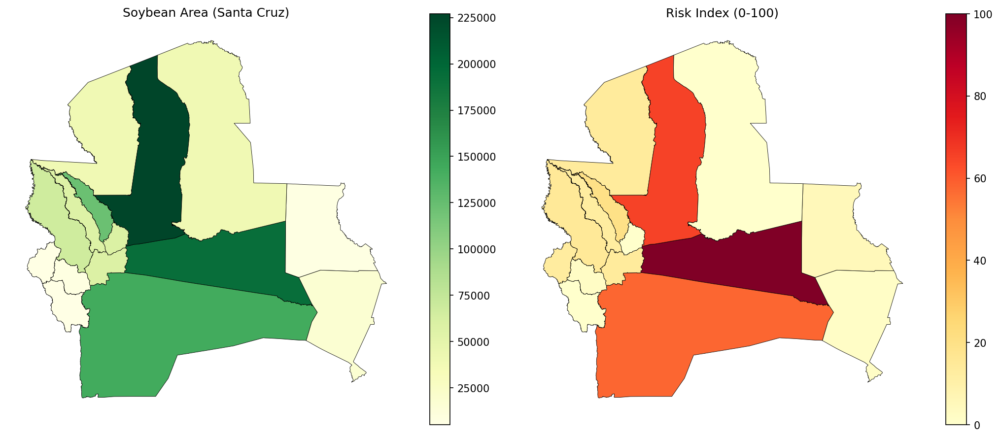

Displaying map for: Soybean in Cochabamba


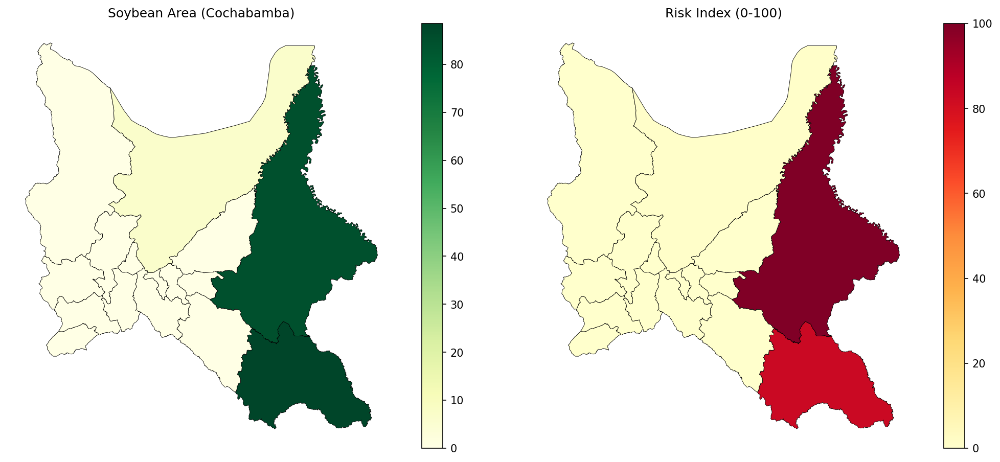

Displaying map for: Soybean in La Paz


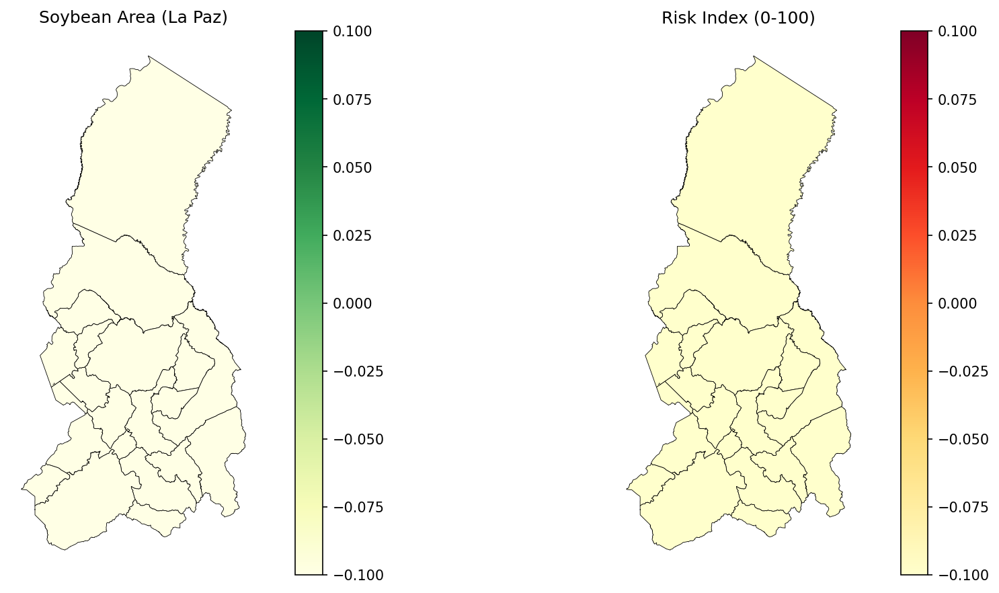

Displaying map for: Maize in Santa Cruz


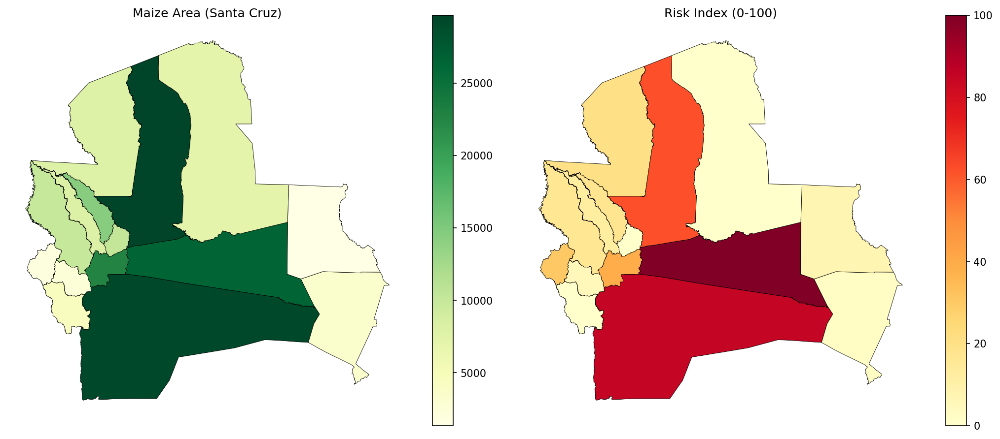

Displaying map for: Maize in Cochabamba


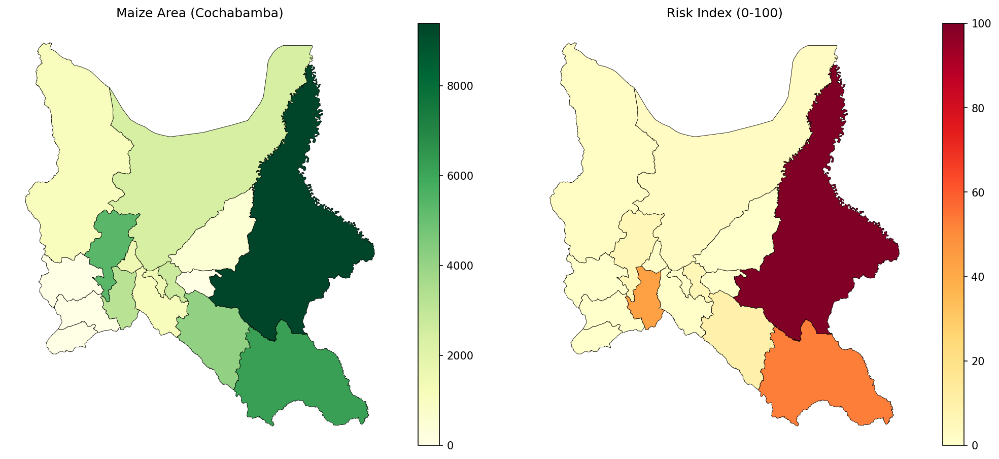

Displaying map for: Maize in La Paz


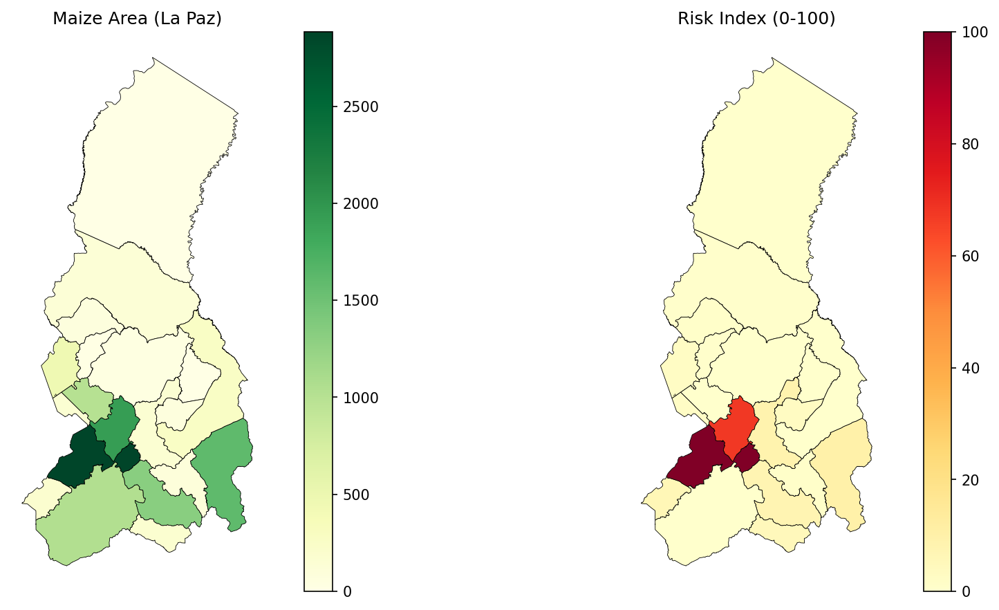

Displaying map for: Potato in Santa Cruz


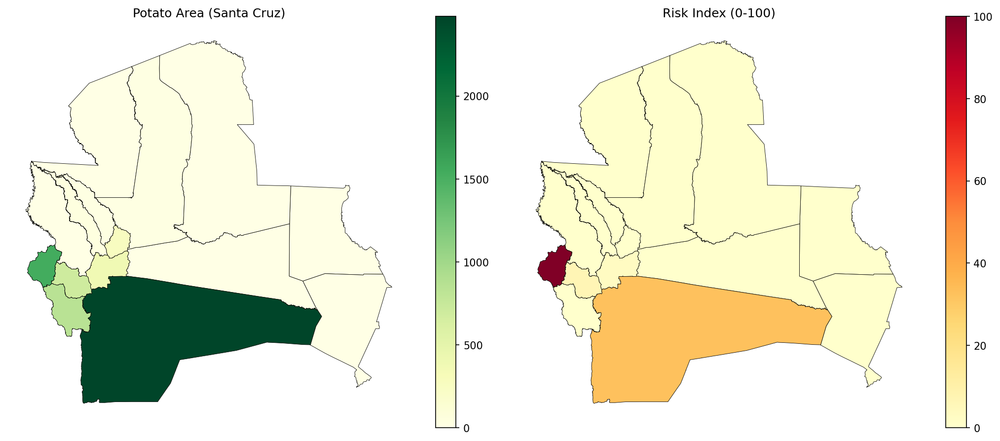

Displaying map for: Potato in Cochabamba


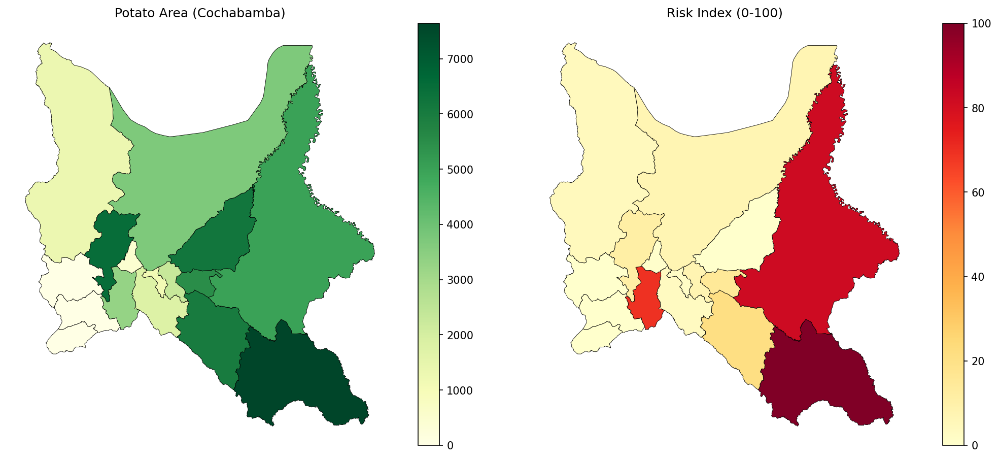

Displaying map for: Potato in La Paz


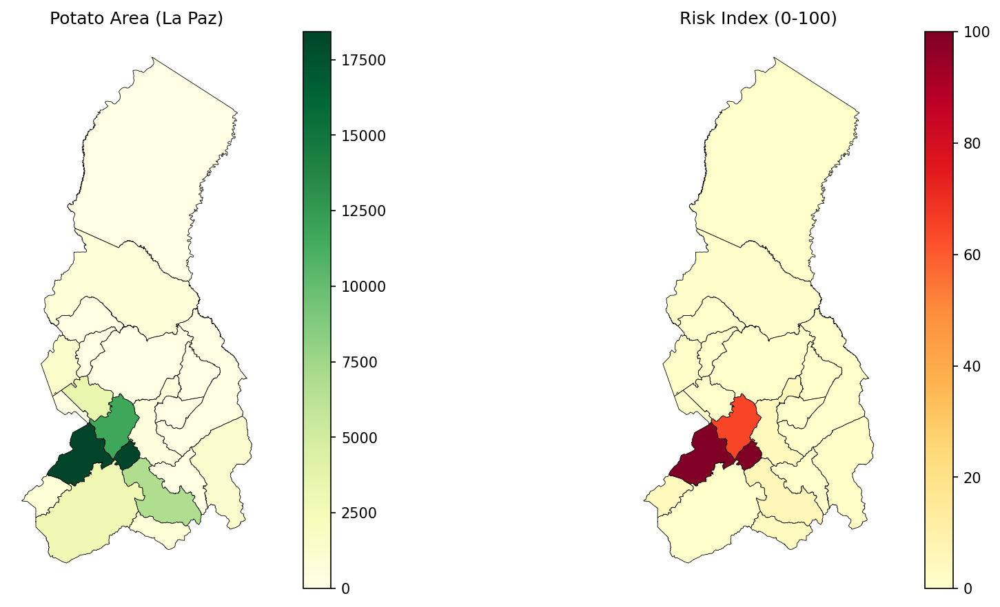

In [ ]:
summary_df = pd.read_csv(os.path.join(OUT_DIR, "summary_all_scenarios.csv"))

for index, row in summary_df.iterrows():
    crop_name = row["Crop"]
    region = row["Region"]
    scenario_name = f"{crop_name}_{region.replace(' ','_')}"
    image_path = os.path.join(OUT_DIR, f"{scenario_name}.png")
    print(f"Displaying map for: {crop_name} in {region}")
    display(Image(image_path))


Displaying map for: Soybean in Santa Cruz


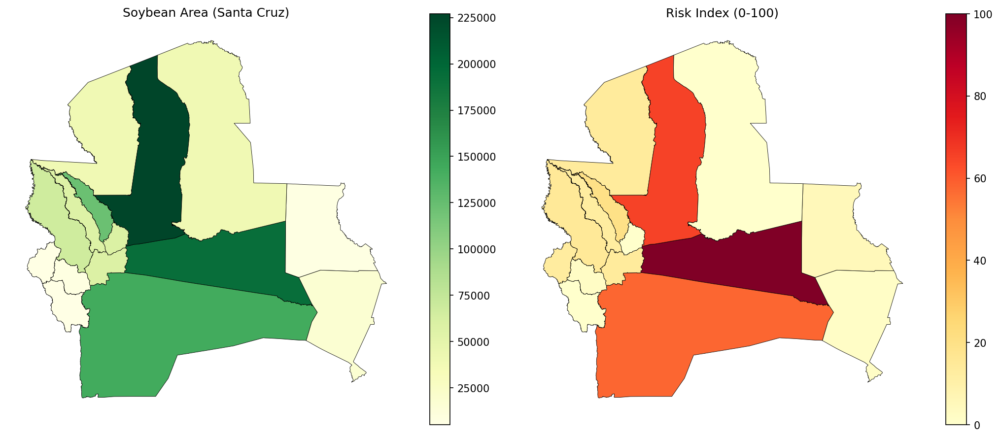

Displaying map for: Soybean in Cochabamba


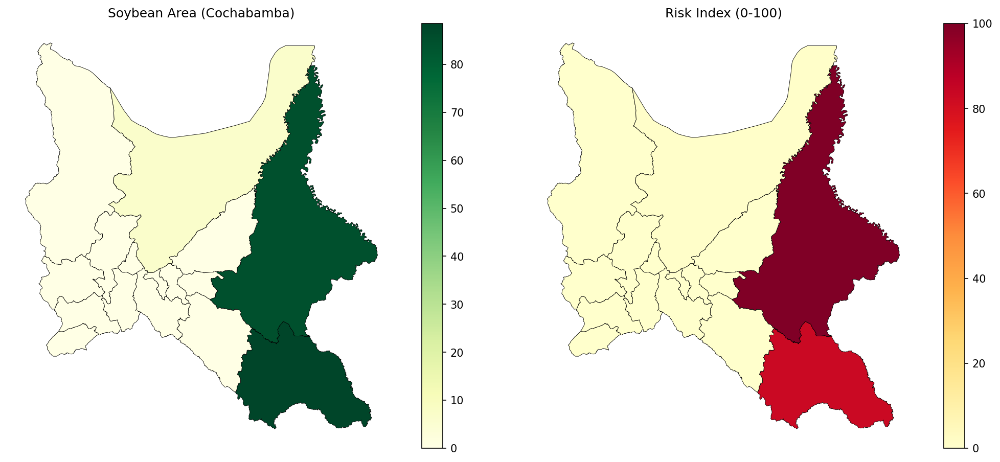

Displaying map for: Soybean in La Paz


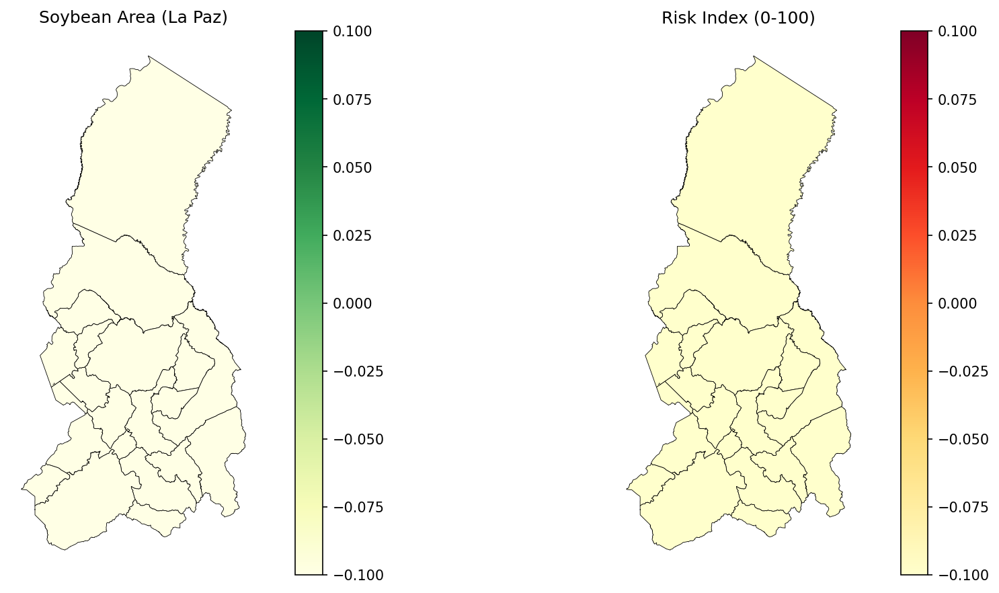

Displaying map for: Maize in Santa Cruz


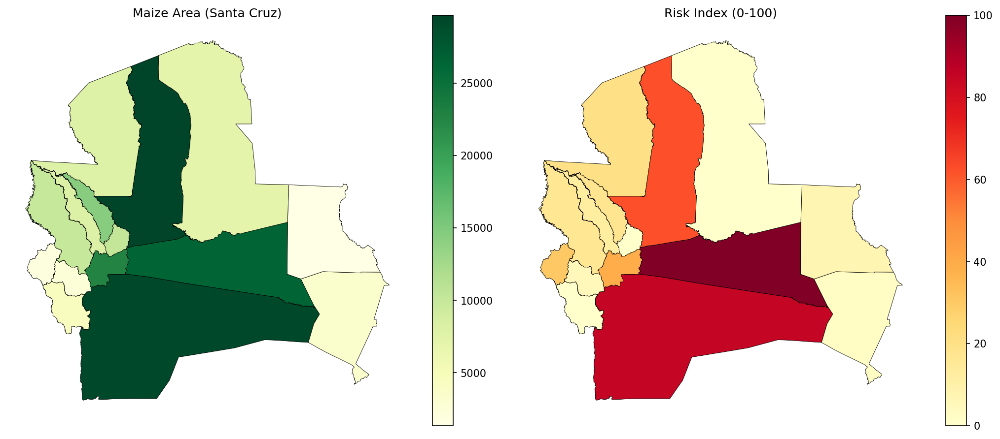

Displaying map for: Maize in Cochabamba


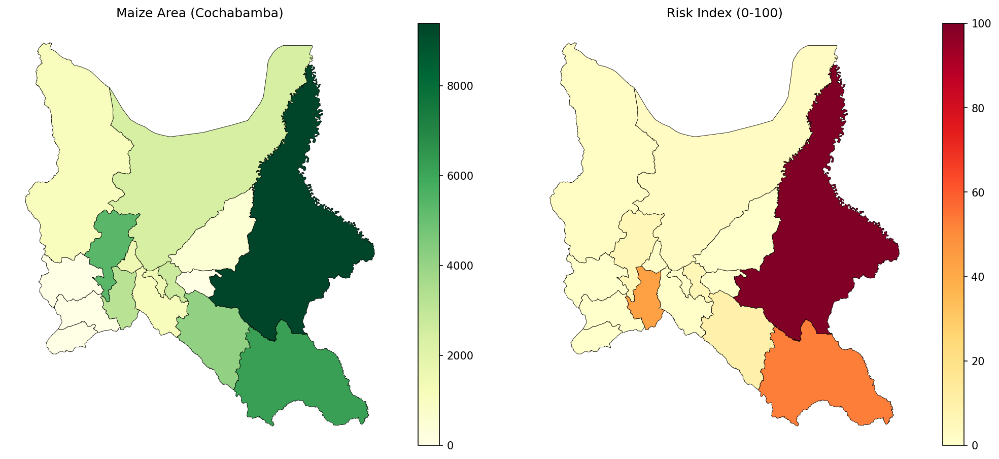

Displaying map for: Maize in La Paz


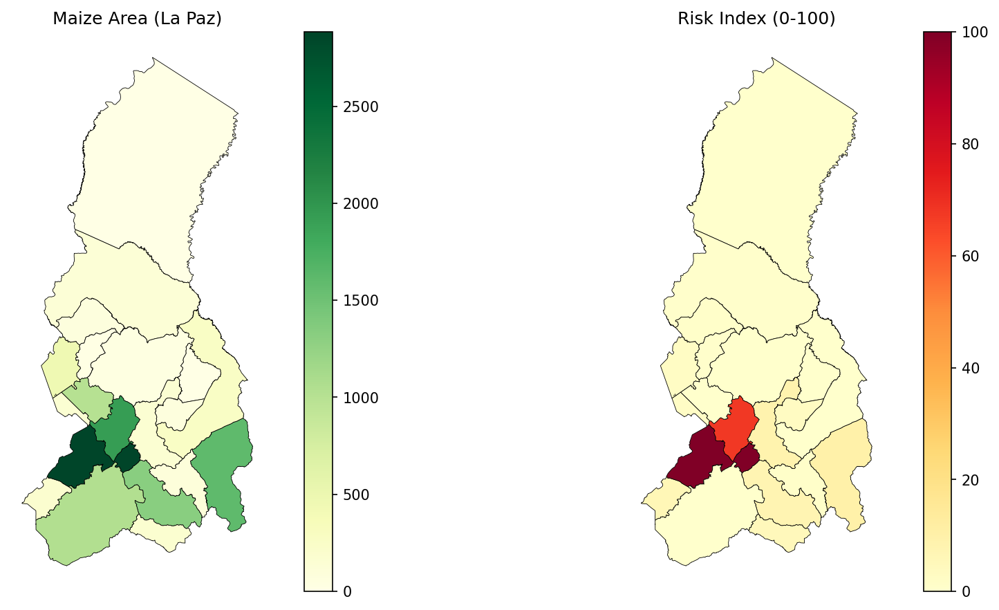

Displaying map for: Potato in Santa Cruz


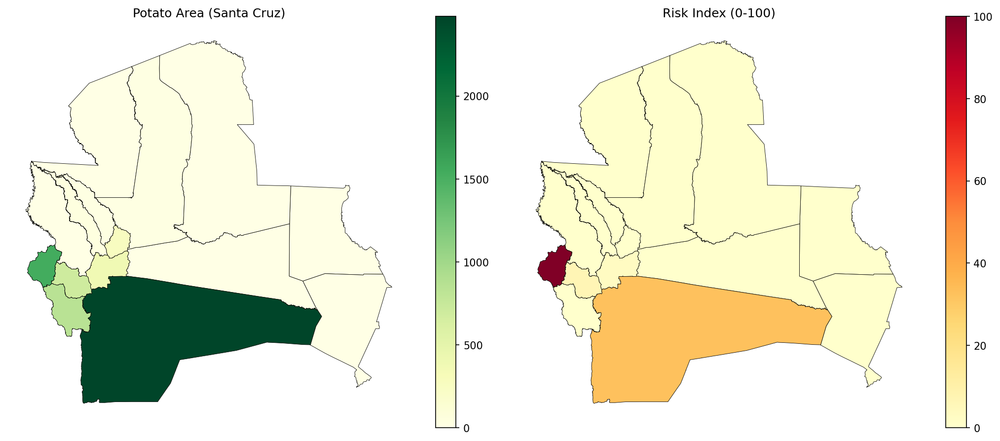

Displaying map for: Potato in Cochabamba


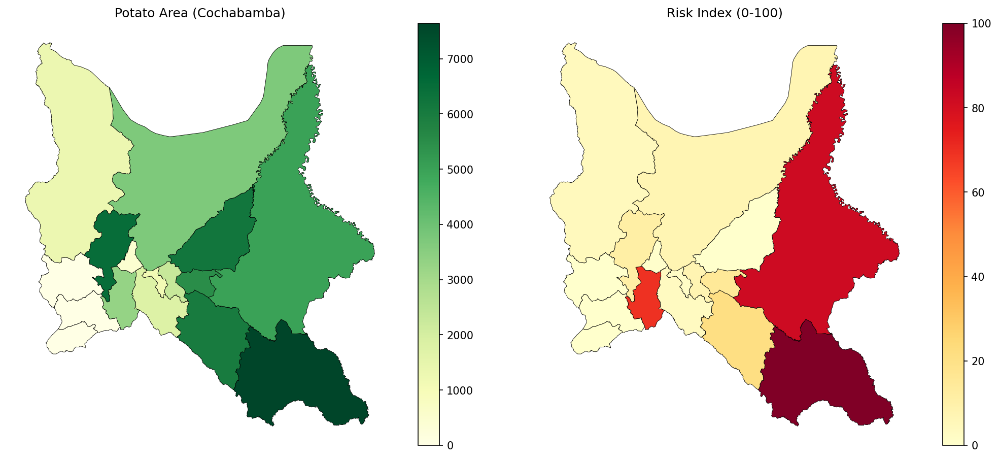

Displaying map for: Potato in La Paz


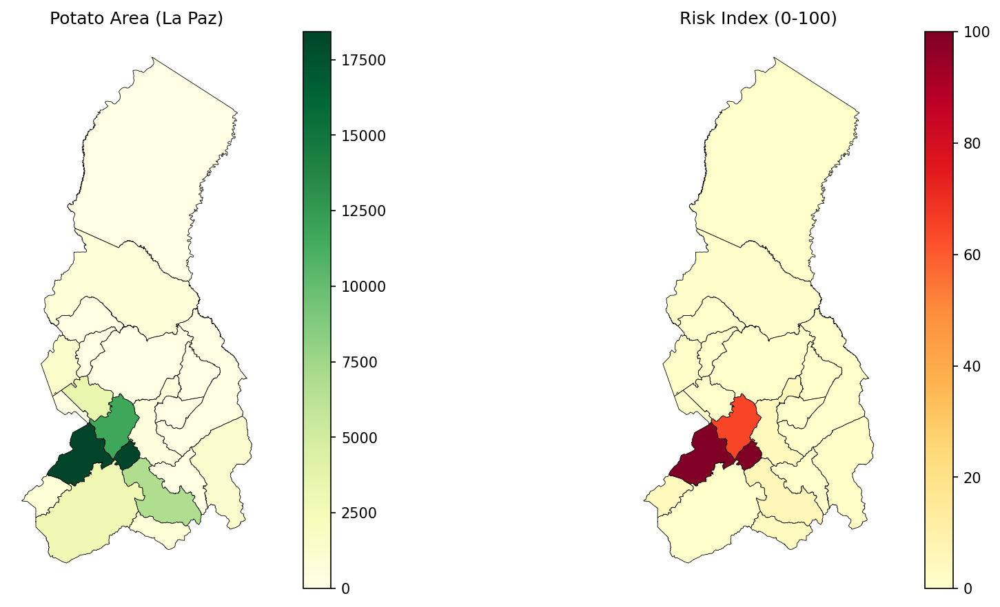

In [ ]:
summary_df = pd.read_csv(os.path.join(OUT_DIR, "summary_all_scenarios.csv"))

for index, row in summary_df.iterrows():
    crop_name = row["Crop"]
    region = row["Region"]
    scenario_name = f"{crop_name}_{region.replace(' ','_')}"
    image_path = os.path.join(OUT_DIR, f"{scenario_name}.png")
    print(f"Displaying map for: {crop_name} in {region}")
    display(Image(image_path))

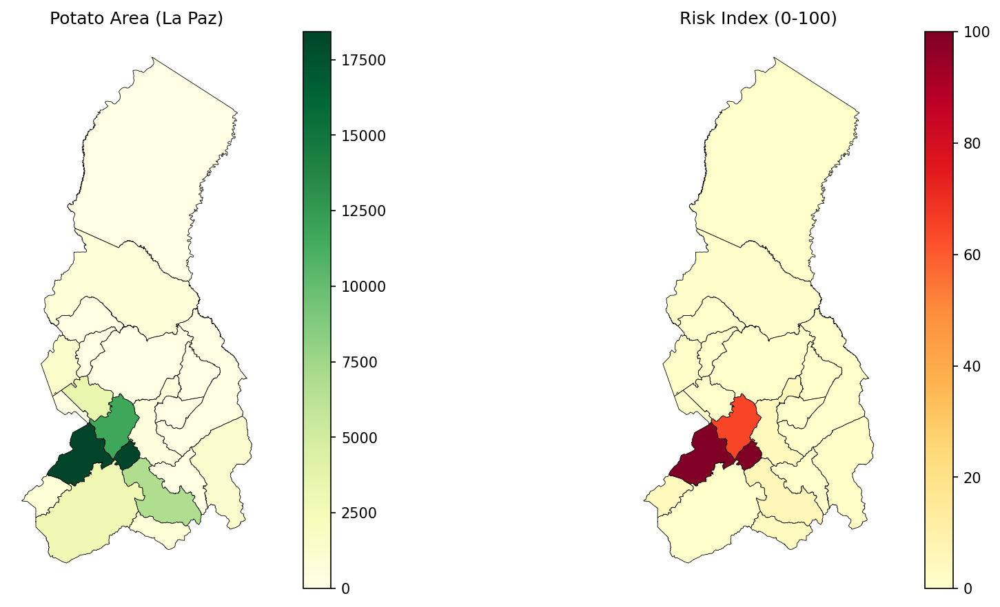

In [ ]:
from IPython.display import Image, display
display(Image(os.path.join(OUT_DIR, f"{scenario}.png")))

##Final Dashboard

In [ ]:
fig, ax = plt.subplots(figsize=(14,8))

for crop in sum_df["Crop"].unique():

    sub = sum_df[sum_df["Crop"] == crop]

    ax.plot(
        sub["Region"],
        sub["Total_Exposure"],
        marker="o",
        linewidth=2,
        label=crop
    )

ax.set_title("Total Exposure by Region and Crop")
ax.set_ylabel("Exposure")
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "summary_dashboard.png"),
    dpi=150
)

## Summary Dashboard

In [ ]:
summary_df = pd.read_csv(os.path.join(OUT_DIR, "summary_all_scenarios.csv"))
display(summary_df)

,Crop,Region,Rule_p25_ha,Total_Area_ha,Avg_Road_Risk,Total_Exposure,Max_Index,N_Above_Rule
0,Soybean,Santa Cruz,12585.9,1050089.7,6.43,4744372.3,100.0,11
1,Soybean,Cochabamba,45.9,180.2,8.91,4200.9,100.0,2
2,Soybean,La Paz,0.0,0.0,4.45,0.0,0.0,20
3,Maize,Santa Cruz,3973.6,179687.0,6.43,953645.2,100.0,11
4,Maize,Cochabamba,1105.4,38912.8,8.91,676352.2,100.0,10
5,Maize,La Paz,104.1,11635.5,4.45,60519.5,100.0,13
6,Potato,Santa Cruz,31.4,6309.8,6.43,87155.0,100.0,7
7,Potato,Cochabamba,1237.1,50871.7,8.91,718997.3,100.0,11
8,Potato,La Paz,118.4,49621.2,4.45,385432.0,100.0,13


##Version 3

In [ ]:
!pip install -q rasterio geopandas rasterstats pandas matplotlib openpyxl loguru

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.7 MB/s eta 0:00:00


In [ ]:
import os
import zipfile
import random
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
from rasterstats import zonal_stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from loguru import logger
from IPython.display import Image, display

In [ ]:
from google.colab import files
uploaded = files.upload()
if "spam2010v2r0_global_harv_area.geotiff.zip" in uploaded.keys():
    print("Successfully uploaded: spam2010v2r0_global_harv_area.geotiff.zip")

Saving spam2010v2r0_global_harv_area.geotiff.zip to spam2010v2r0_global_harv_area.geotiff (2).zip


In [ ]:
from google.colab import files
uploaded = files.upload()
if "41467_2019_10442_MOESM3_ESM.xlsx" in uploaded.keys():
    print("Successfully uploaded: 41467_2019_10442_MOESM3_ESM.xlsx")

Saving 41467_2019_10442_MOESM3_ESM.xlsx to 41467_2019_10442_MOESM3_ESM.xlsx
Successfully uploaded: 41467_2019_10442_MOESM3_ESM.xlsx


In [ ]:
from google.colab import files
uploaded = files.upload()
if "41467_2019_10442_MOESM3_ESM (2).xlsx" in uploaded.keys():
    print("Successfully uploaded: 41467_2019_10442_MOESM3_ESM (2).xlsx")

Saving 41467_2019_10442_MOESM3_ESM (2).xlsx to 41467_2019_10442_MOESM3_ESM (2).xlsx
Successfully uploaded: 41467_2019_10442_MOESM3_ESM (2).xlsx


##CONFIG

In [ ]:
SPAM_ZIP   = "spam2010v2r0_global_harv_area.geotiff (2).zip"
SHAPE_ZIP  = "gadm41_BOL_shp.zip"
RISK_FILE  = "41467_2019_10442_MOESM3_ESM.xlsx"
SPAM_DIR   = "spam_tifs"
TEMP_DIR   = "temp_shp"
OUTPUT_DIR = "scenario_outputs_v2"
# Fixed random seed — results are reproducible across every run.
# Any integer works; changing it gives a different (but still stable) sample.
# See: https://en.wikipedia.org/wiki/Random_seed
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# All available departments — regions are randomly sampled from this list.
# This makes the pipeline trivially scalable to other countries by replacing
# the department list.
ALL_DEPARTMENTS = [
    "Santa Cruz", "Cochabamba", "La Paz", "Chuquisaca",
    "Tarija", "Beni", "Pando", "Oruro", "Potosi",
]

# Randomly select N_REGIONS departments for the analysis.
# With seed=42 this always produces the same selection.
N_REGIONS = 3

# Crops: SPAM 2010 code → display name
# Chosen to span Bolivia's three main agro-ecological zones:
#   Soybean → commercial lowland, Santa Cruz soy belt
#   Maize   → widespread staple, present in all regions
#   Potato  → highland staple, Cochabamba / La Paz dominant
CROPS = {
    "SOYB": "Soybean",
    "MAIZ": "Maize",
    "POTA": "Potato",
}

# Market / logistics hub — fixed destination for all supply-chain paths.
# La Paz is Bolivia's main logistics and administrative hub.
MARKET_DEPT = "La Paz"

# Inclusion rule: named as a rule (not a "threshold").
# Rationale: retaining districts above the p25 of their nonzero crop-area
# distribution keeps 75% of productive districts while excluding marginal or
# data-sparse areas. This is consistent with spatial crop-risk literature
# (e.g. Müller et al. 2021, Nature Food, doi:10.1038/s43016-021-00400-y).
# The percentile is computed live per crop × region, so it adapts automatically
# when i change the region or crop.
INCLUSION_PERCENTILE = 25

# Damage Decay Function (DDF) — differentiates crops by perishability.
# Physical interpretation: for every hour of additional transport delay caused
# by poor road conditions, the crop loses this fraction of its value.
# Delay is computed from path rel_risk: delay_factor = 1 + mean(rel_risk on path)
# Effective hours = (base_distance / base_speed) × delay_factor
#
# Source for perishability rates:
#   FAO (2011). Global food losses and food waste. FAO, Rome.
#   ISBN 978-92-5-107205-9. Table 1 (transport-stage loss rates by commodity).
#
# Soybean / Maize: dry grains → minimal biological decay; risk = physical
#   road vibration damage only (cracks, moisture ingress at low rate).
# Potato: fresh tuber → moderate perishability; bruising and moisture loss
#   accumulate rapidly with vibration and temperature fluctuation during delay.
DAMAGE_DECAY_PER_HOUR = {
    "Soybean": 0.00010,   # 0.010 % per hour
    "Maize":   0.00015,   # 0.015 % per hour
    "Potato":  0.00200,   # 0.200 % per hour
}

# Representative transport parameters for Bolivia
BASE_SPEED_KMH  = 50    # average effective speed on paved Bolivian roads (km/h)
BASE_DIST_KM    = 300   # representative farm-to-market distance (km)

# Colours
BG, PANEL, TC, GC = "#0f1117", "#1a1d27", "white", "#2e3148"
CROP_COLOR = {"Soybean": "#2ecfa8", "Maize": "#ffd93d", "Potato": "#ff6b6b"}

##Setup

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SPAM_DIR,   exist_ok=True)
os.makedirs(TEMP_DIR,   exist_ok=True)

# [FIX 5] Randomly select regions with fixed seed
REGIONS = random.sample(ALL_DEPARTMENTS, N_REGIONS)
logger.info(f"Random seed: {RANDOM_SEED}  →  Selected regions: {REGIONS}")

# Extract GADM shapefile (only once)
print(f"Attempting to extract: {SHAPE_ZIP}")
print(f"Files in current directory: {os.listdir('.')}")
with zipfile.ZipFile(SHAPE_ZIP, "r") as z:
    z.extractall(TEMP_DIR)

# Extract only the three SPAM rasters we need
# Naming: spam2010V2r0_global_H_{CROP}_A.tif
#   H = harvested area (ha per pixel, ~10 km resolution)
#   A = all farming technologies combined
with zipfile.ZipFile(SPAM_ZIP) as z:
    for code in CROPS:
        fname = f"spam2010V2r0_global_H_{code}_A.tif"
        fpath = os.path.join(SPAM_DIR, fname)
        if not os.path.exists(fpath):
            z.extract(fname, SPAM_DIR)
            logger.info(f"Extracted: {fname}")

2026-04-26 04:35:58.936 | INFO     | __main__:<cell line: 0>:7 - Random seed: 42  →  Selected regions: ['Cochabamba', 'Santa Cruz', 'Beni']


Attempting to extract: gadm41_BOL_shp.zip
Files in current directory: ['.config', 'scenario_outputs_v2', 'spam2010v2r0_global_harv_area.geotiff.zip', 'temp_shp', 'spam2010v2r0_global_harv_area.geotiff (2).zip', 'spam_tifs', '41467_2019_10442_MOESM3_ESM.xlsx', '.ipynb_checkpoints', 'spam2010v2r0_global_harv_area.geotiff (1).zip', 'gadm41_BOL_shp.zip', 'sample_data']


2026-04-26 04:35:59.189 | INFO     | __main__:<cell line: 0>:25 - Extracted: spam2010V2r0_global_H_SOYB_A.tif
2026-04-26 04:35:59.291 | INFO     | __main__:<cell line: 0>:25 - Extracted: spam2010V2r0_global_H_MAIZ_A.tif
2026-04-26 04:35:59.400 | INFO     | __main__:<cell line: 0>:25 - Extracted: spam2010V2r0_global_H_POTA_A.tif


In [ ]:

gdf = gpd.read_file(os.path.join(TEMP_DIR, "gadm41_BOL_2.shp"))
gdf["NAME_1"] = gdf["NAME_1"].str.encode("latin-1").str.decode("utf-8", errors="replace")
gdf["NAME_2"] = gdf["NAME_2"].str.encode("latin-1").str.decode("utf-8", errors="replace")

# GID_2_risk: converts shapefile key (BOL.3.1_2) → risk dataset key (BOL_3_1_1)
gdf["GID_2_risk"] = (
    gdf["GID_2"]
    .str.replace(".", "_", regex=False)
    .str.replace(r"_2$", "_1", regex=True)
)
logger.info(f"GADM: {len(gdf)} provinces, {gdf['NAME_1'].nunique()} departments")

2026-04-26 04:49:54.039 | INFO     | __main__:<cell line: 0>:11 - GADM: 112 provinces, 9 departments


##Load road risk

In [ ]:
wb      = load_workbook(RISK_FILE, read_only=True)
r_rows  = list(wb["(risk_data.csv)"].iter_rows(values_only=True))
h_rows  = list(wb["(hazard_data.csv)"].iter_rows(values_only=True))

risk_df = pd.DataFrame(
    r_rows[1:], columns=["idx", "GID_2", "tot_risk_road", "all_risk_road", "rel_risk"]
)
haz_df  = pd.DataFrame(
    h_rows[1:], columns=["idx", "GID_2", "dom_hz", "areadeg"]
)
for col in ["tot_risk_road", "all_risk_road", "rel_risk"]:
    risk_df[col] = pd.to_numeric(risk_df[col], errors="coerce")

bol_risk = (
    risk_df[risk_df["GID_2"].str.startswith("BOL", na=False)]
    .merge(haz_df[["GID_2", "dom_hz"]], on="GID_2", how="left")
)
logger.info(
    f"Road risk: {len(bol_risk)} Bolivia districts  |  "
    f"tot_risk_road: {bol_risk['tot_risk_road'].min():.3f}–"
    f"{bol_risk['tot_risk_road'].max():.3f} USD/yr  |  "
    f"rel_risk: {bol_risk['rel_risk'].min():.4f}–"
    f"{bol_risk['rel_risk'].max():.4f}"
)

2026-04-26 04:50:02.232 | INFO     | __main__:<cell line: 0>:18 - Road risk: 95 Bolivia districts  |  tot_risk_road: 0.002–40.434 USD/yr  |  rel_risk: 0.0002–1.0239



##Build province adjacency graph

In [ ]:
# Multi-district path — the pipeline now accumulates risk across ALL
# provinces traversed on the route from the origin department to the market hub,
# not just within the origin department.
#
# Method:
#   Nodes  = all 112 Bolivia GADM-2 provinces
#   Edges  = shared boundaries (detected via 100 m buffer in projected CRS)
#   Weight = average rel_risk of the two endpoint provinces
#   Path   = minimum-risk path (Dijkstra) from origin → market department
#   Path risk = mean rel_risk across all nodes on the path (the "accumulated
#               corridor risk" a shipment actually faces)

# Project to UTM 20S for accurate buffering (avoids CRS warning)
gdf_proj = gdf.to_crs("EPSG:3857")
gdf_buf  = gdf_proj.copy()
gdf_buf.geometry = gdf_buf.geometry.buffer(100)   # 100 m buffer

adj = gpd.sjoin(
    gdf_buf[["GID_2", "NAME_1", "NAME_2", "geometry"]],
    gdf_proj[["GID_2", "NAME_1", "NAME_2", "geometry"]],
    how="left", predicate="intersects",
)
adj = adj[adj["GID_2_left"] != adj["GID_2_right"]]

# Build rel_risk lookup for node attributes
risk_median = bol_risk["rel_risk"].median()
risk_lkp    = dict(zip(bol_risk["GID_2"], bol_risk["rel_risk"].fillna(risk_median)))
gdf["rel_risk_node"] = gdf["GID_2_risk"].map(risk_lkp).fillna(risk_median)
node_risk   = dict(zip(gdf["GID_2"], gdf["rel_risk_node"]))

G = nx.Graph()
for _, row in gdf.iterrows():
    G.add_node(
        row["GID_2"],
        name=row["NAME_2"],
        dept=row["NAME_1"],
        rel_risk=node_risk[row["GID_2"]],
        cx=row.geometry.centroid.x,
        cy=row.geometry.centroid.y,
    )
for _, row in adj.iterrows():
    n1, n2 = row["GID_2_left"], row["GID_2_right"]
    if not G.has_edge(n1, n2):
        G.add_edge(n1, n2, risk_weight=(node_risk.get(n1, 0) + node_risk.get(n2, 0)) / 2)

logger.info(f"Adjacency graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")


def compute_path_risk(G, origin_dept: str, dest_dept: str) -> tuple:
    """
    Find the minimum-risk path from any province in origin_dept to any
    province in dest_dept and return (mean_rel_risk_along_path, n_hops).
    Samples up to 3 origin and 3 destination nodes for computational efficiency.
    """
    origin_nodes = [n for n, d in G.nodes(data=True) if d["dept"] == origin_dept]
    dest_nodes   = [n for n, d in G.nodes(data=True) if d["dept"] == dest_dept]
    if not origin_nodes or not dest_nodes:
        return np.nan, 0
    best_risk, best_hops = np.inf, 0
    for src in origin_nodes[:3]:
        for tgt in dest_nodes[:3]:
            try:
                path       = nx.shortest_path(G, src, tgt, weight="risk_weight")
                mean_risk  = np.mean([G.nodes[n]["rel_risk"] for n in path])
                if mean_risk < best_risk:
                    best_risk, best_hops = mean_risk, len(path)
            except nx.NetworkXNoPath:
                pass
    return (best_risk if best_risk < np.inf else np.nan), best_hops

2026-04-26 04:52:01.157 | INFO     | __main__:<cell line: 0>:46 - Adjacency graph: 112 nodes, 305 edges



##9-scenario loop

In [ ]:
summary_rows = []

for crop_code, crop_name in CROPS.items():
    tif_path   = os.path.join(SPAM_DIR, f"spam2010V2r0_global_H_{crop_code}_A.tif")
    decay_rate = DAMAGE_DECAY_PER_HOUR[crop_name]

    for region in REGIONS:
        sid = f"{crop_name}_{region.replace(' ', '_')}"
        logger.info(f"Scenario: {sid}")

        # Clip GADM to department
        reg = gdf[gdf["NAME_1"] == region].copy().reset_index(drop=True)

        # Zonal statistics
        # all_touched=False → centroid-based pixel assignment;
        # avoids double-counting pixels that straddle province boundaries.
        stats      = zonal_stats(reg, tif_path, stats=["sum", "mean", "max"],
                                 nodata=-1, all_touched=False)
        reg["harv_ha"] = [s["sum"]  if s["sum"]  is not None else 0.0 for s in stats]
        reg["mean_ha"] = [s["mean"] if s["mean"] is not None else 0.0 for s in stats]
        reg["max_ha"]  = [s["max"]  if s["max"]  is not None else 0.0 for s in stats]

        total_harv     = reg["harv_ha"].sum()
        reg["crop_frac"] = reg["harv_ha"] / total_harv if total_harv > 0 else 0.0

        #  Inclusion rule: p25 computed live from the actual nonzero
        # distribution in this specific crop × region combination.
        # The function adapts automatically — no hardcoded values.
        nonzero_vals = reg.loc[reg["harv_ha"] > 0, "harv_ha"].values
        inclusion_threshold = (
            float(np.percentile(nonzero_vals, INCLUSION_PERCENTILE))
            if len(nonzero_vals) > 0 else 0.0
        )
        reg["included"] = reg["harv_ha"] >= inclusion_threshold
        logger.info(
            f"  Inclusion rule p{INCLUSION_PERCENTILE}: "
            f"{inclusion_threshold:.0f} ha  "
            f"({reg['included'].sum()}/{len(reg)} provinces included)"
        )

        # Merge local road risk on GID_2_risk
        merged = reg.merge(
            bol_risk[["GID_2", "tot_risk_road", "all_risk_road", "rel_risk", "dom_hz"]]
            .rename(columns={"GID_2": "GID_2_risk"}),
            on="GID_2_risk", how="left",
        )
        merged["tot_risk_road"] = pd.to_numeric(merged["tot_risk_road"], errors="coerce")
        merged["rel_risk"]      = pd.to_numeric(merged["rel_risk"],      errors="coerce")

        # Multi-district path risk
        # Accumulate rel_risk across ALL districts traversed from this region
        # to the market hub — not just the origin district.
        if region != MARKET_DEPT:
            path_risk, path_hops = compute_path_risk(G, region, MARKET_DEPT)
        else:
            path_risk = float(merged["rel_risk"].mean())
            path_hops = 1
        logger.info(
            f"  Path {region}→{MARKET_DEPT}: "
            f"mean_rel_risk={path_risk:.3f}, hops={path_hops}"
        )

        # Damage Decay Function
        # Delay factor: roads with higher rel_risk slow effective transport speed.
        # Effective hours = base_hours × (1 + path_mean_rel_risk)
        # Loss fraction  = decay_rate × effective_hours  (capped at 100%)
        base_hours      = BASE_DIST_KM / BASE_SPEED_KMH
        delay_factor    = 1 + (path_risk if not np.isnan(path_risk) else 0.0)
        effective_hours = base_hours * delay_factor
        loss_fraction   = min(decay_rate * effective_hours, 1.0)

        # Crop-risk exposure metric
        # exposure_i = harv_ha_i × local_rel_risk_i × loss_fraction_crop
        # Units: ha × (dimensionless) × (dimensionless)
        #      = ha-equivalent of crop value at risk from road conditions
        # local rel_risk captures within-region spatial variation;
        # loss_fraction captures crop-specific vulnerability to delays.
        merged["exposure_raw"] = (
            merged["harv_ha"] * merged["rel_risk"].fillna(0) * loss_fraction
        )

        # Standardise exposure to [0, 1] within each scenario
        # so values are immediately interpretable by decision-makers:
        # 0 = lowest-exposure province, 1 = highest-exposure province.
        emin, emax = merged["exposure_raw"].min(), merged["exposure_raw"].max()
        merged["exposure_norm"] = (
            (merged["exposure_raw"] - emin) / (emax - emin)
            if emax > emin else 0.0
        )

        n_match = merged["tot_risk_road"].notna().sum()
        logger.info(
            f"  total_harv={total_harv:,.0f} ha  "
            f"delay_factor=×{delay_factor:.3f}  "
            f"loss_fraction={loss_fraction*100:.3f}%  "
            f"exposure_sum={merged['exposure_raw'].sum():,.2f}"
        )

        # Save CSV
        out_cols = [
            "GID_2", "NAME_1", "NAME_2",
            "harv_ha", "mean_ha", "max_ha", "crop_frac", "included",
            "tot_risk_road", "all_risk_road", "rel_risk", "dom_hz",
            "exposure_raw", "exposure_norm",
        ]
        csv_path = os.path.join(OUTPUT_DIR, f"{sid}.csv")
        merged[out_cols].to_csv(csv_path, index=False)

        # Three-panel scenario map
        fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor=BG)
        fig.suptitle(
            f"{crop_name}  ·  {region}  →  {MARKET_DEPT}  (market hub)\n"
            f"Inclusion rule: p{INCLUSION_PERCENTILE} = {inclusion_threshold:.0f} ha  ·  "
            f"Path rel_risk = {path_risk:.3f}  ·  "
            f"Delay ×{delay_factor:.2f}  ·  "
            f"Crop loss fraction = {loss_fraction*100:.3f}%  "
            f"(decay rate: {decay_rate*100:.3f}%/hr)",
            color=TC, fontsize=9.5, fontweight="bold",
        )
        for ax in axes:
            ax.set_facecolor(BG)
            for sp in ax.spines.values():
                sp.set_visible(False)
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

        # Left: harvested area
        merged.plot(column="harv_ha", cmap="YlGn", ax=axes[0],
                    edgecolor=GC, linewidth=0.5, legend=True,
                    missing_kwds={"color": "#1a1d27"},
                    legend_kwds={"label": f"{crop_name} area (ha)",
                                 "orientation": "horizontal", "shrink": 0.6,
                                 "pad": 0.02, "aspect": 25, "fraction": 0.04})
        excluded = merged[~merged["included"]]
        if len(excluded):
            excluded.plot(ax=axes[0], color="none", edgecolor="#ff6b6b",
                          linewidth=1.5, linestyle="--", zorder=3)
        axes[0].set_title(
            f"Harvested Area (ha)\ndashed red = excluded (below p{INCLUSION_PERCENTILE}: {inclusion_threshold:.0f} ha)",
            color=TC, fontsize=9, pad=5,
        )

        # Centre: local road risk (rel_risk)
        if merged["rel_risk"].notna().sum() > 0:
            merged.plot(column="rel_risk", cmap="YlOrRd", ax=axes[1],
                        edgecolor=GC, linewidth=0.5, legend=True,
                        missing_kwds={"color": "#1a1d27"},
                        legend_kwds={"label": "rel_risk (EAD USD/km road/yr)",
                                     "orientation": "horizontal", "shrink": 0.6,
                                     "pad": 0.02, "aspect": 25, "fraction": 0.04})
        axes[1].set_title(
            "Local Road Risk  (rel_risk)\nKoks et al. 2019, Nat. Comms. 10:2677",
            color=TC, fontsize=9, pad=5,
        )

        # Right: normalised exposure [0–1]
        if merged["exposure_norm"].sum() > 0:
            merged.plot(column="exposure_norm", cmap="RdPu", ax=axes[2],
                        edgecolor=GC, linewidth=0.5, legend=True,
                        missing_kwds={"color": "#1a1d27"},
                        legend_kwds={"label": "Normalised exposure [0 = lowest, 1 = highest]",
                                     "orientation": "horizontal", "shrink": 0.6,
                                     "pad": 0.02, "aspect": 25, "fraction": 0.04})
        else:
            merged.plot(ax=axes[2], color="#1a1d27", edgecolor=GC, linewidth=0.5)
            axes[2].text(0.5, 0.5, "No exposure\n(zero crop area or no risk data)",
                         transform=axes[2].transAxes, ha="center", va="center",
                         color=TC, fontsize=10)
        axes[2].set_title(
            "Supply-Chain Risk Exposure (normalised 0–1)\nharv_ha × local_rel_risk × crop_loss_fraction",
            color=TC, fontsize=9, pad=5,
        )

        plt.tight_layout()
        png_path = os.path.join(OUTPUT_DIR, f"{sid}.png")
        plt.savefig(png_path, dpi=150, bbox_inches="tight", facecolor=BG)
        plt.close()
        logger.info(f"  Saved: {csv_path}  +  {png_path}")

        summary_rows.append({
            "scenario"              : sid,
            "crop"                  : crop_name,
            "region"                : region,
            "inclusion_rule"        : f"p{INCLUSION_PERCENTILE}",
            "inclusion_threshold_ha": round(inclusion_threshold, 1),
            "n_provinces"           : len(merged),
            "n_included"            : int(reg["included"].sum()),
            "n_risk_matched"        : int(n_match),
            "total_harv_ha"         : round(total_harv, 1),
            "path_mean_rel_risk"    : round(path_risk, 4) if not np.isnan(path_risk) else None,
            "path_hops"             : path_hops,
            "delay_factor"          : round(delay_factor, 3),
            "loss_fraction_pct"     : round(loss_fraction * 100, 4),
            "total_exposure_raw"    : round(merged["exposure_raw"].sum(), 4),
            "avg_exposure_norm"     : round(merged["exposure_norm"].mean(), 4),
            "avg_tot_risk"          : round(merged["tot_risk_road"].mean(), 4),
        })

2026-04-26 04:55:38.822 | INFO     | __main__:<cell line: 0>:9 - Scenario: Soybean_Cochabamba
2026-04-26 04:55:39.098 | INFO     | __main__:<cell line: 0>:35 -   Inclusion rule p25: 46 ha  (2/16 provinces included)
2026-04-26 04:55:39.106 | INFO     | __main__:<cell line: 0>:58 -   Path Cochabamba→La Paz: mean_rel_risk=0.129, hops=6
2026-04-26 04:55:39.108 | INFO     | __main__:<cell line: 0>:92 -   total_harv=180 ha  delay_factor=×1.129  loss_fraction=0.068%  exposure_sum=0.06
2026-04-26 04:55:41.230 | INFO     | __main__:<cell line: 0>:177 -   Saved: scenario_outputs_v2/Soybean_Cochabamba.csv  +  scenario_outputs_v2/Soybean_Cochabamba.png
2026-04-26 04:55:41.234 | INFO     | __main__:<cell line: 0>:9 - Scenario: Soybean_Santa_Cruz
2026-04-26 04:55:41.816 | INFO     | __main__:<cell line: 0>:35 -   Inclusion rule p25: 12586 ha  (11/15 provinces included)
2026-04-26 04:55:41.825 | INFO     | __main__:<cell line: 0>:58 -   Path Santa Cruz→La Paz: mean_rel_risk=0.132, hops=11
2026-04-26 

##Summary CSV

In [ ]:
sum_df  = pd.DataFrame(summary_rows)
sum_csv = os.path.join(OUTPUT_DIR, "summary_all_scenarios.csv")
sum_df.to_csv(sum_csv, index=False)

logger.info("=" * 68)
logger.info("SUMMARY — All 9 Scenarios")
logger.info("\n" + sum_df[[
    "crop", "region", "total_harv_ha", "n_included",
    "path_mean_rel_risk", "loss_fraction_pct", "avg_exposure_norm",
]].to_string(index=False))
logger.info(f"Saved: {sum_csv}")

2026-04-26 04:57:27.301 | INFO     | __main__:<cell line: 0>:5 - ====================================================================
2026-04-26 04:57:27.303 | INFO     | __main__:<cell line: 0>:6 - SUMMARY — All 9 Scenarios
2026-04-26 04:57:27.309 | INFO     | __main__:<cell line: 0>:7 - 
   crop     region  total_harv_ha  n_included  path_mean_rel_risk  loss_fraction_pct  avg_exposure_norm
Soybean Cochabamba          180.2           2              0.1288             0.0677             0.1239
Soybean Santa Cruz      1050089.7          11              0.1320             0.0679             0.1996
Soybean       Beni         2006.1           6              0.1265             0.0676             0.2749
  Maize Cochabamba        38912.8          10              0.1288             0.1016             0.2541
  Maize Santa Cruz       179687.0          11              0.1320             0.1019             0.1634
  Maize       Beni         6798.8           6              0.1265             0.1014 

##Story-driven summary dashboard

In [ ]:
# Every panel answers the "so what?" question:
# Research question: Which crop-region combinations need priority road investment?
# Narrative: Potato in Cochabamba has a 20× higher damage decay rate than soy.
# Combined with moderate road risk, it faces the highest normalised exposure.
# Decision implication: road upgrades in Cochabamba potato corridors yield
# the highest food-loss reduction per USD invested.

crops_list  = sum_df["crop"].unique().tolist()
region_list = sum_df["region"].unique().tolist()
x = np.arange(len(region_list))
w = 0.25

def make_ax(fig, rect, title=None):
    ax = fig.add_axes(rect, facecolor=PANEL)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(colors=TC, labelsize=8)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_color(TC)
    if title:
        ax.set_title(title, color=TC, fontsize=10, fontweight="bold", pad=6)
    return ax


fig = plt.figure(figsize=(22, 20), facecolor=BG)

# Dashboard header — states the question and the answer
fig.text(0.5, 0.982,
         "Which crop-region combinations need priority road investment?",
         ha="center", va="top", fontsize=17, fontweight="bold", color=TC)
fig.text(0.5, 0.966,
         "Supply-chain exposure = harvested area  ×  local road risk  ×  "
         "crop-specific damage decay along full farm-to-market path\n"
         "Road risk: Koks et al. (2019) Nat. Comms. 10:2677  ·  "
         "Crop area: SPAM 2010 v2r0  ·  "
         f"Regions: random sample (seed={RANDOM_SEED})  ·  "
         f"Market hub: {MARKET_DEPT}",
         ha="center", va="top", fontsize=8.5, color="#6b7590")

# Panel A: Road risk distribution — answers supervisor's "does it go 0–10?"
ax_risk = make_ax(fig, [0.05, 0.765, 0.275, 0.175],
                  title="A  Road Risk Distribution (Bolivia, n=95)\n"
                        "tot_risk_road = EAD (USD/yr), rel_risk = EAD per km road")
ax_risk.hist(bol_risk["rel_risk"].dropna(), bins=20,
             color="#4e8cff", alpha=0.8, edgecolor=BG, linewidth=0.3)
for pct, lbl in zip([25, 50, 75], ["p25", "p50", "p75"]):
    v = float(bol_risk["rel_risk"].quantile(pct / 100))
    ax_risk.axvline(v, color="white", lw=1, ls="--", alpha=0.6)
    ax_risk.text(v, ax_risk.get_ylim()[1] * 0.82,
                 f" {lbl}\n {v:.2f}", color="white", fontsize=7)
ax_risk.set_xlabel("rel_risk (EAD USD per km road per yr)", color=TC, fontsize=8)
ax_risk.set_ylabel("Number of provinces", color=TC, fontsize=8)
ax_risk.text(0.97, 0.97,
             "NOT 0–10 scale.\nBounded by road\nconstruction costs.\nBolivia max: 40.4 USD/yr",
             transform=ax_risk.transAxes, ha="right", va="top",
             color="#6b7590", fontsize=6.5,
             bbox=dict(facecolor=BG, edgecolor="none", pad=2))
ax_risk.grid(axis="y", color=GC, linewidth=0.4, alpha=0.5)

# Panel B: Damage Decay — the crop differentiator
ax_ddf = make_ax(fig, [0.375, 0.765, 0.265, 0.175],
                 title="B  Damage Decay Function by Crop\n"
                       "Loss fraction rises faster for perishable crops at same road risk")
rr_range  = np.linspace(0, 1.0, 60)
base_hrs  = BASE_DIST_KM / BASE_SPEED_KMH
for crop, rate in DAMAGE_DECAY_PER_HOUR.items():
    losses = [min(rate * base_hrs * (1 + r), 1.0) * 100 for r in rr_range]
    ax_ddf.plot(rr_range, losses, color=CROP_COLOR[crop], lw=2.5, label=crop)
ax_ddf.set_xlabel("Path mean rel_risk (farm → market)", color=TC, fontsize=8)
ax_ddf.set_ylabel("Crop loss fraction (%)", color=TC, fontsize=8)
ax_ddf.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax_ddf.grid(color=GC, linewidth=0.4, alpha=0.4)
ax_ddf.text(0.03, 0.97,
            "Source: FAO (2011)\nGlobal Food Losses\nand Food Waste",
            transform=ax_ddf.transAxes, va="top",
            color="#6b7590", fontsize=6.5)

# Panel C: Inclusion rule — p25 distribution per crop × region
ax_incl = make_ax(fig, [0.69, 0.765, 0.275, 0.175],
                  title="C  Inclusion Rule: p25 Threshold per Scenario\n"
                        "Computed live — adapts to each crop × region combination")
bar_data = sum_df[["crop", "region", "inclusion_threshold_ha"]].copy()
for i, crop in enumerate(crops_list):
    sub = bar_data[bar_data.crop == crop]
    vals = [sub[sub.region == r]["inclusion_threshold_ha"].values[0]
            for r in region_list]
    bars = ax_incl.bar(x + i*w, vals, width=w, color=CROP_COLOR[crop],
                       label=crop, alpha=0.85, edgecolor=BG, linewidth=0.4)
    for bar, v in zip(bars, vals):
        ax_incl.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                     f"{v:.0f}", ha="center", color=TC, fontsize=6.5)
ax_incl.set_xticks(x + w)
ax_incl.set_xticklabels(region_list, color=TC, fontsize=8)
ax_incl.set_ylabel("p25 inclusion threshold (ha)", color=TC, fontsize=8)
ax_incl.legend(fontsize=7, labelcolor=TC, framealpha=0)
ax_incl.grid(axis="y", color=GC, linewidth=0.4, alpha=0.5)

# Panel D: ★ Priority matrix — normalised exposure (the main "so what" panel)
ax_exp = make_ax(fig, [0.05, 0.520, 0.42, 0.215],
                 title="D  ★  Priority Matrix: Avg Normalised Exposure per Scenario\n"
                       "0 = lowest-risk province, 1 = highest-risk province within scenario\n"
                       "→ Potato in perishability-sensitive corridors drives highest exposure")
for i, crop in enumerate(crops_list):
    vals = [sum_df[(sum_df.crop == crop) & (sum_df.region == r)]["avg_exposure_norm"].values[0]
            for r in region_list]
    bars = ax_exp.bar(x + i*w, vals, width=w, color=CROP_COLOR[crop],
                      label=crop, alpha=0.85, edgecolor=BG, linewidth=0.4)
    for bar, v in zip(bars, vals):
        ax_exp.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f"{v:.3f}", ha="center", color=TC, fontsize=7.5, fontweight="bold")
ax_exp.set_xticks(x + w)
ax_exp.set_xticklabels(region_list, color=TC, fontsize=9)
ax_exp.set_ylabel("Avg normalised exposure [0–1]", color=TC, fontsize=9)
ax_exp.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax_exp.grid(axis="y", color=GC, linewidth=0.4, alpha=0.5)
ax_exp.set_ylim(0, ax_exp.get_ylim()[1] * 1.18)

# Panel E: Path risk vs loss fraction — shows why crops differ
ax_scatter = make_ax(fig, [0.55, 0.520, 0.42, 0.215],
                     title="E  Path Risk vs Loss Fraction by Scenario\n"
                           "Potato separates vertically — same road risk, "
                           "far more economic damage\n"
                           "→ Road investment yields 20× more benefit for potato than soy")
for _, row in sum_df.iterrows():
    if pd.isna(row["path_mean_rel_risk"]):
        continue
    ax_scatter.scatter(
        row["path_mean_rel_risk"], row["loss_fraction_pct"],
        s=np.sqrt(max(row["total_harv_ha"], 1)) / 8 + 20,
        color=CROP_COLOR[row["crop"]],
        alpha=0.88, edgecolors="none", zorder=3,
    )
    ax_scatter.annotate(
        f"{row['crop'][:3]}/{row['region'][:3]}",
        (row["path_mean_rel_risk"], row["loss_fraction_pct"]),
        textcoords="offset points", xytext=(5, 2),
        color=TC, fontsize=7.5, alpha=0.9,
    )
for crop in crops_list:
    ax_scatter.scatter([], [], s=55, color=CROP_COLOR[crop], label=crop, alpha=0.88)
ax_scatter.legend(fontsize=8, labelcolor=TC, framealpha=0, loc="upper left")
ax_scatter.set_xlabel("Path mean rel_risk (farm → market hub)", color=TC, fontsize=9)
ax_scatter.set_ylabel("Crop loss fraction (%)", color=TC, fontsize=9)
ax_scatter.grid(color=GC, linewidth=0.4, alpha=0.4)

# Panel F: Road risk distribution per region
ax_rbox = make_ax(fig, [0.05, 0.295, 0.42, 0.195],
                  title="F  Road Risk Distribution per Region\n"
                        "(tot_risk_road — Expected Annual Damages, USD/yr/district  ·  "
                        "Koks et al. 2019)")
region_colors = dict(zip(region_list, ["#4e8cff", "#ffd93d", "#ff6b6b"]))
gdf_risk = gdf.merge(
    bol_risk[["GID_2", "tot_risk_road", "rel_risk"]].rename(columns={"GID_2": "GID_2_risk"}),
    on="GID_2_risk", how="left",
)
for region in region_list:
    vals = gdf_risk[gdf_risk["NAME_1"] == region]["tot_risk_road"].dropna().values
    if len(vals) == 0:
        continue
    col = region_colors[region]
    ax_rbox.hist(vals, bins=10, alpha=0.65, color=col, label=region,
                 edgecolor=BG, linewidth=0.3)
    ax_rbox.axvline(np.median(vals), color=col, lw=1.5, ls="--", alpha=0.8)
ax_rbox.set_xlabel("tot_risk_road (USD/yr)", color=TC, fontsize=8)
ax_rbox.set_ylabel("Number of provinces", color=TC, fontsize=8)
ax_rbox.legend(fontsize=8, labelcolor=TC, framealpha=0)
ax_rbox.grid(axis="y", color=GC, linewidth=0.4, alpha=0.5)

# Panel G: Summary table
ax_tbl = fig.add_axes([0.55, 0.295, 0.42, 0.195])
ax_tbl.set_facecolor(PANEL)
for sp in ax_tbl.spines.values():
    sp.set_visible(False)
ax_tbl.axis("off")
ax_tbl.set_title("G  Path Risk Parameters by Scenario",
                 color=TC, fontsize=10, fontweight="bold", pad=6, loc="left")

tbl_sm = sum_df[["crop", "region", "path_mean_rel_risk", "path_hops",
                  "delay_factor", "loss_fraction_pct", "avg_exposure_norm"]].copy()
tbl_sm.columns = ["Crop", "Region", "Path Risk", "Hops",
                   "Delay ×", "Loss %", "Norm. Exp."]
for col in ["Path Risk", "Delay ×", "Loss %", "Norm. Exp."]:
    tbl_sm[col] = tbl_sm[col].round(4)

t = ax_tbl.table(
    cellText=tbl_sm.values.tolist(),
    colLabels=tbl_sm.columns.tolist(),
    loc="center", cellLoc="center",
)
t.auto_set_font_size(False)
t.set_fontsize(8)
t.scale(1, 1.55)
for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor(GC)
    if r == 0:
        cell.set_facecolor("#1e253a")
        cell.set_text_props(color=TC, fontweight="bold")
    else:
        cell.set_facecolor("#0d1120" if r % 2 == 0 else "#101525")
        cell.set_text_props(color=TC if r % 2 == 0 else "#aab4cc")

# Panel H: Full results table
ax_full = fig.add_axes([0.03, 0.04, 0.94, 0.225])
ax_full.set_facecolor(PANEL)
for sp in ax_full.spines.values():
    sp.set_visible(False)
ax_full.axis("off")
ax_full.set_title(
    f"H  Full Results Table — All 9 Scenarios  "
    f"(random seed={RANDOM_SEED}  ·  market hub={MARKET_DEPT}  ·  "
    f"inclusion rule=p{INCLUSION_PERCENTILE}  ·  "
    f"Koks et al. 2019 road risk)",
    color=TC, fontsize=9, fontweight="bold", pad=8, loc="left",
)

tbl_full = sum_df[[
    "crop", "region", "inclusion_threshold_ha", "n_included",
    "total_harv_ha", "path_mean_rel_risk", "path_hops",
    "delay_factor", "loss_fraction_pct", "avg_exposure_norm",
]].copy()
tbl_full.columns = [
    "Crop", "Region", "p25 (ha)", "Incl.",
    "Area (ha)", "Path Risk", "Hops",
    "Delay ×", "Loss %", "Norm. Exp.",
]
tbl_full["Area (ha)"]   = tbl_full["Area (ha)"].apply(lambda v: f"{v:,.0f}")
tbl_full["Path Risk"]   = tbl_full["Path Risk"].round(3)
tbl_full["Delay ×"]     = tbl_full["Delay ×"].round(3)
tbl_full["Loss %"]      = tbl_full["Loss %"].round(4)
tbl_full["Norm. Exp."]  = tbl_full["Norm. Exp."].round(4)

tf = ax_full.table(
    cellText=tbl_full.values.tolist(),
    colLabels=tbl_full.columns.tolist(),
    loc="center", cellLoc="center",
)
tf.auto_set_font_size(False)
tf.set_fontsize(8.5)
tf.scale(1, 1.65)
for (r, c), cell in tf.get_celld().items():
    cell.set_edgecolor(GC)
    if r == 0:
        cell.set_facecolor("#1e253a")
        cell.set_text_props(color=TC, fontweight="bold")
    else:
        cell.set_facecolor("#0d1120" if r % 2 == 0 else "#101525")
        cell.set_text_props(color=TC if r % 2 == 0 else "#aab4cc")

dash_path = os.path.join(OUTPUT_DIR, "summary_dashboard.png")
plt.savefig(dash_path, dpi=150, bbox_inches="tight", facecolor=BG)
plt.close()
logger.info(f"Dashboard saved: {dash_path}")
logger.info(f"All outputs in: {OUTPUT_DIR}/")

2026-04-26 05:09:53.309 | INFO     | __main__:<cell line: 0>:252 - Dashboard saved: scenario_outputs_v2/summary_dashboard.png
2026-04-26 05:09:53.310 | INFO     | __main__:<cell line: 0>:253 - All outputs in: scenario_outputs_v2/


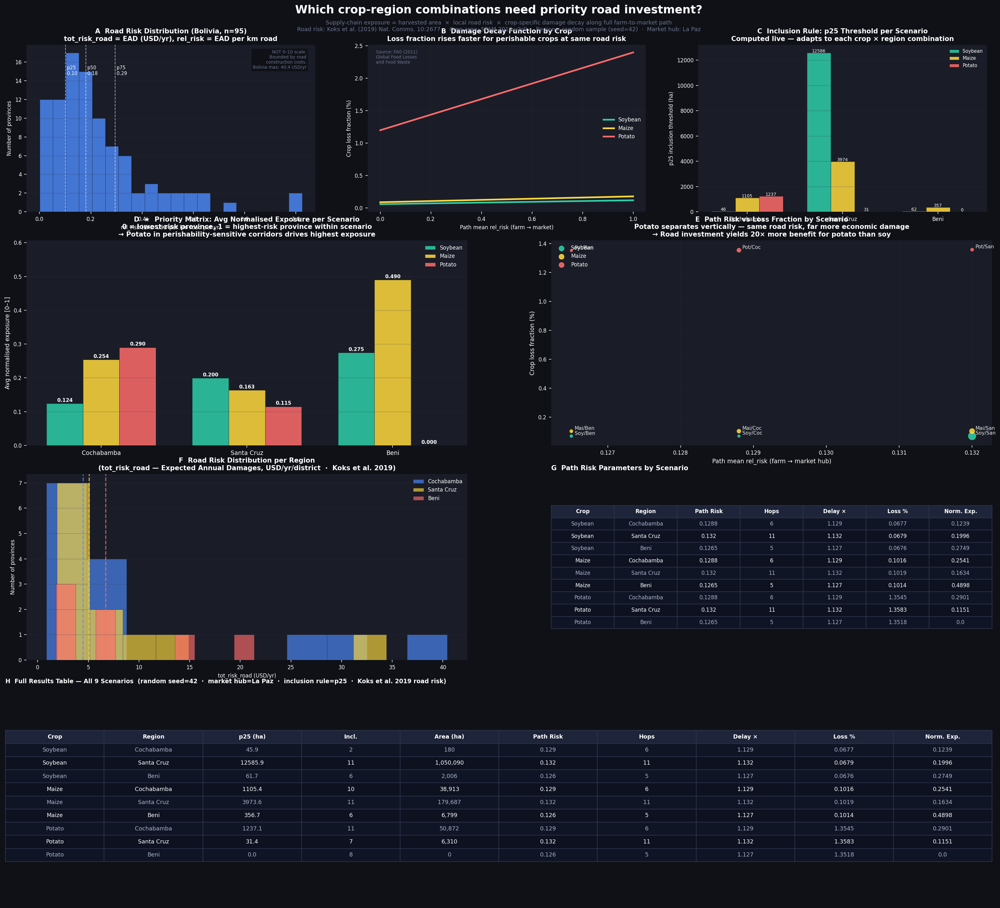

In [ ]:
from IPython.display import Image, display
display(Image(os.path.join(OUTPUT_DIR, "summary_dashboard.png")))